# Mini-Projeto: Modelagem e Solução de Problemas com Aprendizado por Reforço

**Alunos:**

- EDUARDO DA PAZ RODRIGUES
- HENRIQUE PEIXOTO RIBEIRO
- IZAIAS SATURNINO DE LIMA NETO
- RICCO VASCONCELLOS CONSTANTE SOARES

Neste notebook, vocês irão desenvolver o projeto prático da disciplina. O objetivo é aplicar os algoritmos tabulares clássicos em um ambiente de espaço contínuo (`MountainCar-v0`), utilizando técnicas de discretização, conforme o enunciado.

Deixe, neste colab, somente o código necessário para treinar os agentes com a parametrização mais vantajosa e gerar os gráficos, além do relatório em texto, na **análise dos resultados** e no **diário de bordo**. O restante da experimentação pode ser feito em outros colabs e ambientes. O diário de bordo deve comentar essa jornada e pode referenciar esses outros artefatos.

## 0. Configuração do ambiente e dos experimentos

A célula abaixo instala (se necessário) e importa as dependências. Funciona no Colab e localmente.

In [1]:
# ==============================================================================
# CONFIGURAÇÃO DO AMBIENTE: dependências e imports
# ==============================================================================
# Funciona tanto no Colab quanto localmente (Jupyter). Só instala o que estiver faltando.
import importlib.util
import subprocess
import sys

IN_COLAB = 'google.colab' in sys.modules

# nome do módulo -> pacote do pip
_DEPENDENCIAS = {
    'gymnasium': 'gymnasium[classic-control]',
    'pygame': 'pygame-ce',       # renderização do MountainCar (render_mode='rgb_array')
    'moviepy': 'moviepy',        # usado pelo wrapper RecordVideo para gravar .mp4
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn',
}
_faltando = [pip for mod, pip in _DEPENDENCIAS.items() if importlib.util.find_spec(mod) is None]
if _faltando:
    print('Instalando dependências ausentes:', _faltando)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *_faltando])

import base64
import glob
import hashlib
import itertools
import json
import os
import pickle
import random
import re
import time
import warnings

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from gymnasium.wrappers import RecordVideo
from IPython.display import HTML, display

try:  # scipy é opcional (usado só para o quantil da distribuição t)
    from scipy import stats as _scipy_stats
except ImportError:
    _scipy_stats = None

warnings.filterwarnings('ignore', category=UserWarning, module='gymnasium')

print(f'Python {sys.version.split()[0]} | gymnasium {gym.__version__} | numpy {np.__version__} | '
      f'pandas {pd.__version__} | seaborn {sns.__version__} | Colab: {IN_COLAB}')

Python 3.14.7 | gymnasium 1.4.0 | numpy 2.5.4 | pandas 3.1.0 | seaborn 0.13.2 | Colab: False


### CONFIG — escolhas experimentais

Todas as escolhas que definem o experimento (resoluções da discretização, hiperparâmetros de cada algoritmo, nº de seeds e de episódios) ficam **centralizadas na célula abaixo**. Os valores presentes são apenas *placeholders* para o código rodar.

- `MODO_TESTE_RAPIDO = True` roda uma versão minúscula (2 seeds, 5 episódios) só para checar que tudo executa — **não** usar esses números como resultado.
- Com `MODO_TESTE_RAPIDO = False`, *Run all* executa o experimento completo (≥ 10 seeds) e salva os resultados em disco; com `REUTILIZAR_RESULTADOS = True`, execuções posteriores apenas recarregam os resultados salvos.

In [2]:
# ==============================================================================
# CONFIG — ESCOLHAS EXPERIMENTAIS
# ==============================================================================
# Valores finais, escolhidos pela busca de hiperparâmetros feita fora deste notebook
# (pasta mini_projeto_busca/: busca.py, fase2.py, rodada2.py; plano e histórico em
# PLANO_EXPERIMENTOS.md). Critério de escolha: desempenho final = média de passos nos
# últimos 50 episódios (menor = melhor), média de 10 seeds. As justificativas estão nas
# células de texto das Tarefas A e B.

# --- Orçamento de execução ----------------------------------------------------------
# MODO_TESTE_RAPIDO = True roda uma versão minúscula (2 seeds, poucos episódios), só
# para verificar que todas as células rodam de ponta a ponta. NÃO use esses números
# como resultado. Para o experimento final, deixe False.
MODO_TESTE_RAPIDO = False

SEEDS = list(range(10))        # >= 10 seeds (exigência do enunciado)
N_EPISODIOS = 500              # nº de episódios de treino por execução (seed)
MAX_PASSOS_EPISODIO = 200      # limite padrão do MountainCar-v0 (wrapper TimeLimit)
MAX_PASSOS_TOTAL = None        # alternativa: orçamento total de passos no ambiente por
                               # execução (None = desativado; usa só N_EPISODIOS)

PASTA_RESULTADOS = 'resultados'  # onde ficam .pkl/.csv/figuras (no Colab: /content/...)
REUTILIZAR_RESULTADOS = True     # True: se a mesma configuração já foi rodada e salva,
                                 # carrega do disco em vez de treinar de novo.
                                 # (Se mudar o CÓDIGO dos agentes, apague a pasta ou use False.)

# --- Tarefa A: discretizações -------------------------------------------------------
# 'bins' = nº de intervalos por dimensão: (posição, velocidade).
# 'bordas' (opcional) = bordas internas de cada dimensão, para grades não uniformes.
DISCRETIZACOES = {
    # uniforme de alta resolução: 40 x 40 = 1.600 células
    'alta_resolucao': {'bins': (40, 40)},
    # uniforme de resolução média: 20 x 20 = 400 células (2ª melhor grade do Dyna-Q)
    'media_resolucao': {'bins': (20, 20)},
    # não uniforme: posição em 6 intervalos uniformes; velocidade em 16 intervalos,
    # mais finos perto de 0 (0,002) e mais largos nos extremos (até 0,02): 96 células
    'vel_detalhada': {'bins': (6, 16), 'bordas': [
        [-0.9, -0.6, -0.3, 0.0, 0.3],
        [-0.05, -0.035, -0.02, -0.012, -0.007, -0.004, -0.002, 0.0,
         0.002, 0.004, 0.007, 0.012, 0.02, 0.035, 0.05]]},
    # não uniforme nas duas dimensões: posição em 18 intervalos (0,05 perto da parede da
    # esquerda, do fundo do vale e do objetivo; até 0,2 no meio) e a velocidade da
    # vel_detalhada: 18 x 16 = 288 células
    'pos_vel_detalhada': {'bins': (18, 16), 'bordas': [
        [-1.15, -1.1, -1.0, -0.85, -0.7, -0.6, -0.55, -0.5, -0.45, -0.4,
         -0.25, -0.05, 0.15, 0.3, 0.4, 0.45, 0.5],
        [-0.05, -0.035, -0.02, -0.012, -0.007, -0.004, -0.002, 0.0,
         0.002, 0.004, 0.007, 0.012, 0.02, 0.035, 0.05]]},
}

# --- Tarefa B: hiperparâmetros por discretização e algoritmo -------------------------
# Parâmetros comuns:
#   alpha              taxa de aprendizado
#   gamma              fator de desconto
#   epsilon_inicial    epsilon no 1º episódio
#   epsilon_final      piso do epsilon
#   decaimento_epsilon fator multiplicativo por episódio (tipo_decaimento='exponencial')
#   tipo_decaimento    'exponencial' ou 'linear' (linear usa episodios_decaimento)
#   q_inicial          valor inicial de todos os Q(s,a)
# Específicos:
#   SARSA(λ): lambda_, tipo_traco ('acumulativo' | 'substituicao'), limiar_traco
#   Dyna-Q:   n_planejamento (N), tipo_modelo ('ultimo' | 'amostral')
_COMUNS = dict(alpha=0.1, gamma=1.0, epsilon_inicial=0.5, epsilon_final=0.01,
               decaimento_epsilon=0.99, tipo_decaimento='exponencial', q_inicial=0.0)

HIPERPARAMETROS = {
    nome_disc: {
        'Q-learning': dict(_COMUNS, q_inicial=-100.0, decaimento_epsilon=0.9),
        'SARSA(λ)':   dict(_COMUNS, lambda_=0.9, tipo_traco='acumulativo'),
        'Dyna-Q':     dict(_COMUNS, n_planejamento=40, tipo_modelo='amostral'),
    }
    for nome_disc in DISCRETIZACOES
}
# Na média resolução e na pos_vel_detalhada, o Dyna-Q usa a melhor configuração encontrada
# para cada uma dessas grades
HIPERPARAMETROS['media_resolucao']['Dyna-Q'].update(q_inicial=-300.0, n_planejamento=20)
HIPERPARAMETROS['pos_vel_detalhada']['Dyna-Q'].update(q_inicial=-300.0, n_planejamento=20)

if MODO_TESTE_RAPIDO:
    # Orçamento minúsculo, pasta separada para não misturar com os resultados reais.
    SEEDS = [0, 1]
    N_EPISODIOS = 5
    MAX_PASSOS_TOTAL = None
    PASTA_RESULTADOS = 'resultados_teste_rapido'
    REUTILIZAR_RESULTADOS = False
    print('*** MODO_TESTE_RAPIDO ativo: os números gerados NÃO são resultados válidos. ***')

os.makedirs(PASTA_RESULTADOS, exist_ok=True)
print(f'{len(SEEDS)} seeds | {N_EPISODIOS} episódios/execução | '
      f'discretizações: {list(DISCRETIZACOES)} | resultados em "{PASTA_RESULTADOS}/"')


10 seeds | 500 episódios/execução | discretizações: ['alta_resolucao', 'media_resolucao', 'vel_detalhada', 'pos_vel_detalhada'] | resultados em "resultados/"


## Tarefa A: Modelagem do Espaço de Estados (Discretização)

Implementem abaixo **duas formas ou resoluções de discretização diferentes**

In [3]:
# ==============================================================================
# TAREFA A: FUNÇÕES DE DISCRETIZAÇÃO
# ==============================================================================
# O estado do MountainCar-v0 é contínuo: obs = (posição, velocidade), com
#   posição   em [-1.2, 0.6]   (o objetivo é atingir posição >= 0.5)
#   velocidade em [-0.07, 0.07]
# Para usar métodos tabulares, mapeamos cada obs para UMA célula de uma grade
# retangular e, em seguida, para um único índice inteiro s em {0, ..., n_estados-1}.


class DiscretizadorGrade:
    """Discretizador por grade retangular, parametrizado pela resolução.

    Modo uniforme (padrão): cada dimensão d é dividida em `bins[d]` intervalos de mesma
    largura entre low[d] e high[d].
    Modo com bordas explícitas (opcional): `bordas[d]` é a lista das bordas INTERNAS da
    dimensão d (len = bins[d] - 1), permitindo grades não uniformes (ex.: mais finas
    perto do topo da montanha). Útil se quiser comparar "formas" e não só resoluções.

    O índice tabular é o índice linear (row-major) da célula:
        s = i_posicao * bins[1] + i_velocidade
    Valores fora de [low, high] são "grudados" na primeira/última célula.
    """

    def __init__(self, bins, low, high, bordas=None, nome=None):
        self.bins = tuple(int(b) for b in bins)
        self.low = np.asarray(low, dtype=float)
        self.high = np.asarray(high, dtype=float)
        assert len(self.bins) == len(self.low) == len(self.high), 'dimensões inconsistentes'
        self.nome = nome or 'x'.join(map(str, self.bins))
        self.n_dims = len(self.bins)
        self.n_estados = int(np.prod(self.bins))

        if bordas is None:
            self.bordas = None
            # escala por dimensão: (x - low) * escala -> posição contínua em "células"
            self._escala = [b / (h - l) for b, l, h in zip(self.bins, self.low, self.high)]
        else:
            self.bordas = [np.asarray(e, dtype=float) for e in bordas]
            for d, e in enumerate(self.bordas):
                assert len(e) == self.bins[d] - 1, f'bordas[{d}] deve ter bins[{d}]-1 valores'
                assert np.all(np.diff(e) > 0), f'bordas[{d}] deve ser estritamente crescente'

        # cópias em listas Python (acesso escalar mais rápido no laço de treino)
        self._low_l = [float(v) for v in self.low]
        # multiplicadores para o índice linear (row-major)
        self._mult = [int(np.prod(self.bins[d + 1:])) for d in range(self.n_dims)]

    def indices(self, obs):
        """Retorna a tupla (i_0, ..., i_{D-1}) da célula que contém `obs`."""
        idx = []
        for d in range(self.n_dims):
            x = float(obs[d])
            if self.bordas is None:
                i = int((x - self._low_l[d]) * self._escala[d])
            else:
                i = int(np.searchsorted(self.bordas[d], x, side='right'))
            idx.append(min(max(i, 0), self.bins[d] - 1))  # recorta para [0, bins-1]
        return tuple(idx)

    def __call__(self, obs):
        """Mapeia uma observação contínua para o índice tabular (int)."""
        return int(sum(i * m for i, m in zip(self.indices(obs), self._mult)))

    def indices_de_estado(self, s):
        """Inverso do índice linear: s -> (i_0, ..., i_{D-1})."""
        return tuple(int(i) for i in np.unravel_index(int(s), self.bins))

    def bordas_dimensao(self, d):
        """Todas as bordas (inclusive low/high) da dimensão d — útil para gráficos."""
        if self.bordas is None:
            return np.linspace(self.low[d], self.high[d], self.bins[d] + 1)
        return np.concatenate([[self.low[d]], self.bordas[d], [self.high[d]]])

    def centro(self, s):
        """Centro (no espaço contínuo) da célula do estado discreto s."""
        idx = self.indices_de_estado(s)
        return np.array([(self.bordas_dimensao(d)[i] + self.bordas_dimensao(d)[i + 1]) / 2
                         for d, i in enumerate(idx)])

    def descricao(self):
        larguras = [np.diff(self.bordas_dimensao(d)) for d in range(self.n_dims)]
        txt = ', '.join(f'dim{d}: {self.bins[d]} bins (largura {w.min():.4g}'
                        + (f'..{w.max():.4g}' if not np.allclose(w, w[0]) else '') + ')'
                        for d, w in enumerate(larguras))
        return f'[{self.nome}] {self.n_estados} estados discretos | {txt}'

    def __repr__(self):
        return f'DiscretizadorGrade(nome={self.nome!r}, bins={self.bins})'


def criar_discretizador(bins, nome=None, bordas=None, env_id='MountainCar-v0'):
    """Cria um discretizador usando os limites do espaço de observação do ambiente."""
    env = gym.make(env_id)
    low, high = env.observation_space.low, env.observation_space.high
    env.close()
    return DiscretizadorGrade(bins, low, high, bordas=bordas, nome=nome)


# Instancia as discretizações definidas na célula CONFIG
DISCRETIZADORES = {nome: criar_discretizador(cfg['bins'], nome=nome, bordas=cfg.get('bordas'))
                   for nome, cfg in DISCRETIZACOES.items()}

for _disc in DISCRETIZADORES.values():
    print(_disc.descricao())

# Verificação rápida: estado inicial típico (posição ~ -0.5, velocidade 0) e extremos
for _disc in DISCRETIZADORES.values():
    exemplos = [(-0.5, 0.0), (-1.2, -0.07), (0.6, 0.07)]
    print(_disc.nome, {ex: (_disc.indices(ex), _disc(ex)) for ex in exemplos})

[alta_resolucao] 1600 estados discretos | dim0: 40 bins (largura 0.045), dim1: 40 bins (largura 0.0035)
[media_resolucao] 400 estados discretos | dim0: 20 bins (largura 0.09), dim1: 20 bins (largura 0.007)
[vel_detalhada] 96 estados discretos | dim0: 6 bins (largura 0.3), dim1: 16 bins (largura 0.002..0.02)
[pos_vel_detalhada] 288 estados discretos | dim0: 18 bins (largura 0.05..0.2), dim1: 16 bins (largura 0.002..0.02)
alta_resolucao {(-0.5, 0.0): ((15, 20), 620), (-1.2, -0.07): ((0, 0), 0), (0.6, 0.07): ((39, 39), 1599)}
media_resolucao {(-0.5, 0.0): ((7, 10), 150), (-1.2, -0.07): ((0, 0), 0), (0.6, 0.07): ((19, 19), 399)}
vel_detalhada {(-0.5, 0.0): ((2, 8), 40), (-1.2, -0.07): ((0, 0), 0), (0.6, 0.07): ((5, 15), 95)}
pos_vel_detalhada {(-0.5, 0.0): ((8, 8), 136), (-1.2, -0.07): ((0, 0), 0), (0.6, 0.07): ((17, 15), 287)}


**Justificativa das discretizações escolhidas (resoluções/formas):**

A ideia geral foi colocar mais estados perto dos lugares e das situações em que acreditamos que a
granularidade é importante, e comparar isso com grades uniformes. Na busca de hiperparâmetros
(pasta `mini_projeto_busca/`, ver `PLANO_EXPERIMENTOS.md`) testamos seis discretizações: três
uniformes, que medem o efeito de *quantas* células existem, e três não uniformes, que medem o
efeito de *onde* elas estão.

- **Uniformes:** `baixa_resolucao` (10 × 10 = 100 células), `media_resolucao` (20 × 20 = 400) e
  `alta_resolucao` (40 × 40 = 1.600). Uma grade grosseira dá muitas visitas por célula, mas agrupa
  situações muito diferentes (na baixa resolução, cada célula cobre 10% da pista). Uma grade fina
  reduz esse agrupamento (aliasing), mas cada célula é visitada poucas vezes em, no máximo, 100 mil
  passos.
- **`pos_detalhada`** (18 × 6 = 108 células): posição mais detalhada (células de 0,05) perto da
  parede da esquerda, onde o carro para e inverte o sentido; do fundo do vale (≈ −0,52), onde todo
  episódio começa e o balanço se forma; e do trecho final antes do objetivo (0,4 a 0,5), onde se
  decide se o carro passa ou volta. A velocidade fica com 6 intervalos uniformes.
- **`vel_detalhada`** (6 × 16 = 96 células): velocidade mais detalhada perto de zero (células de
  0,002). A boa política é basicamente "empurrar no sentido em que o carro já está andando", e
  perto de v ≈ 0 é onde o carro inverte o sentido. Isso separa "quase parado" de "andando" e reduz
  os auto-laços quando o carro está lento. A posição fica com 6 intervalos uniformes.
- **`pos_vel_detalhada`** (18 × 16 = 288 células): combinação das duas, para ver se o detalhe nas
  duas dimensões vale mais que cada uma separadamente.

As duas grades não uniformes simples têm aproximadamente o mesmo número de células da
`baixa_resolucao`, para que a comparação seja sobre a posição das células, e não sobre a quantidade.

No experimento final deste notebook usamos quatro delas: a `alta_resolucao`, melhor grade do
Dyna-Q; a `vel_detalhada`, melhor grade do SARSA(λ); e a `media_resolucao` e a
`pos_vel_detalhada`, as grades seguintes do Dyna-Q, para mostrar as diferenças entre os algoritmos
em cada grade (o motivo está na justificativa dos hiperparâmetros). A `baixa_resolucao` e a
`pos_detalhada` foram usadas na busca, mas não entraram no experimento final.


## Tarefa B: Implementação dos Agentes Tabulares
Implementem os algoritmos solicitados.

In [4]:
# ==============================================================================
# TAREFA B: AGENTES
# ==============================================================================
# Os três agentes compartilham a mesma interface, usada pelo executor da Tarefa C:
#
#     a = agente.iniciar_episodio(s)                 # escolhe a 1ª ação do episódio
#     enquanto o episódio não acabar:
#         s', r, terminou, truncou = env.step(a)     # (s, s' já discretizados)
#         a = agente.passo(s, a, r, s', terminou, truncou)   # aprende e devolve a próxima ação
#         s = s'
#     agente.finalizar_episodio()                    # decai o epsilon
#
# Tratamento do fim de episódio:
#   * terminou=True  -> estado terminal verdadeiro (carro chegou ao topo): alvo = r.
#   * truncou=True   -> corte por limite de tempo (TimeLimit, 200 passos): s' NÃO é terminal,
#                       então ainda fazemos bootstrap a partir de s' (o episódio só é interrompido).
#
# CONTAGEM DE ATUALIZAÇÕES DE VALOR-Q (self.n_atualizacoes) — regra usada:
#   cada vez que a regra de atualização é aplicada a UMA entrada Q(s,a), conta-se 1
#   (mesmo que o valor numérico não mude, ex.: erro TD = 0).
#   * Q-learning: 1 atualização por passo no ambiente.
#   * SARSA(λ):   por passo, conta-se o nº de pares (s,a) com traço de elegibilidade != 0
#                 (todos eles recebem Q(s,a) += α·δ·e(s,a)).
#   * Dyna-Q:     1 atualização real + N atualizações de planejamento por passo no ambiente
#                 (N = n_planejamento; sempre exatamente N, pois o planejamento amostra pares
#                 já observados e, após o 1º passo real, sempre existe ao menos um).


class AgenteTabularBase:
    """Base comum: tabela Q, política epsilon-greedy e decaimento de epsilon."""

    nome = 'base'

    def __init__(self, n_estados, n_acoes, alpha=0.1, gamma=1.0,
                 epsilon_inicial=1.0, epsilon_final=0.01, decaimento_epsilon=0.99,
                 tipo_decaimento='exponencial', episodios_decaimento=None,
                 q_inicial=0.0, seed=None):
        self.n_estados, self.n_acoes = n_estados, n_acoes
        self.alpha, self.gamma = alpha, gamma
        self.epsilon_inicial, self.epsilon_final = epsilon_inicial, epsilon_final
        self.decaimento_epsilon = decaimento_epsilon
        assert tipo_decaimento in ('exponencial', 'linear')
        if tipo_decaimento == 'linear':
            assert episodios_decaimento, "tipo_decaimento='linear' exige episodios_decaimento"
        self.tipo_decaimento, self.episodios_decaimento = tipo_decaimento, episodios_decaimento
        self.epsilon = epsilon_inicial
        self.q_values = np.full((n_estados, n_acoes), float(q_inicial))
        self.rng = np.random.default_rng(seed)   # toda a aleatoriedade do agente vem daqui
        self.n_atualizacoes = 0                  # contador de atualizações de Q (ver regra acima)
        self.episodios_concluidos = 0

    # ---------------- política ----------------
    def Q(self, s, a):
        return self.q_values[s, a]

    def V(self, s):
        return self.q_values[s].max()

    def greedy_action(self, s):
        """argmax_a Q(s,a) com desempate aleatório (importante com Q inicial constante)."""
        q = self.q_values[s]
        melhores = np.flatnonzero(q == q.max())
        if len(melhores) == 1:
            return int(melhores[0])
        return int(self.rng.choice(melhores))

    def act(self, s):
        """Ação epsilon-greedy."""
        if self.rng.random() < self.epsilon:
            return int(self.rng.integers(self.n_acoes))
        return self.greedy_action(s)

    # ---------------- ciclo do episódio ----------------
    def iniciar_episodio(self, s):
        return self.act(s)

    def passo(self, s, a, r, s2, terminou, truncou):
        raise NotImplementedError

    def finalizar_episodio(self):
        self.episodios_concluidos += 1
        self.atualizar_epsilon()

    def atualizar_epsilon(self):
        """Decaimento por episódio: exponencial (eps *= fator) ou linear até episodios_decaimento."""
        if self.tipo_decaimento == 'exponencial':
            self.epsilon = max(self.epsilon_final, self.epsilon * self.decaimento_epsilon)
        else:
            frac = min(1.0, self.episodios_concluidos / self.episodios_decaimento)
            self.epsilon = self.epsilon_inicial + frac * (self.epsilon_final - self.epsilon_inicial)

    # ---------------- utilidades ----------------
    def _atualizar_q_learning(self, s, a, r, s2, terminou):
        """Uma atualização de Q-learning em Q(s,a) (usada pelo baseline e pelo Dyna-Q)."""
        alvo = r if terminou else r + self.gamma * self.q_values[s2].max()
        self.q_values[s, a] += self.alpha * (alvo - self.q_values[s, a])
        self.n_atualizacoes += 1


# ------------------------------------------------------------------------------
# 1) Baseline: Q-learning (TD de 1 passo, off-policy)
# ------------------------------------------------------------------------------
class AgenteQLearning(AgenteTabularBase):
    """Q(s,a) <- Q(s,a) + α [r + γ max_a' Q(s',a') - Q(s,a)].
    Obs.: SARSA(0) equivale ao AgenteSarsaLambda com lambda_=0."""

    nome = 'Q-learning'

    def passo(self, s, a, r, s2, terminou, truncou):
        self._atualizar_q_learning(s, a, r, s2, terminou)
        if terminou or truncou:
            return None
        return self.act(s2)


# ------------------------------------------------------------------------------
# 2) SARSA(λ) com traços de elegibilidade (visão "backward")
# ------------------------------------------------------------------------------
class AgenteSarsaLambda(AgenteTabularBase):
    """SARSA(λ) tabular com traços de elegibilidade e(s,a).

    A cada passo:
        a' ~ epsilon-greedy(s')                       (se s' não for terminal)
        δ  = r + γ Q(s',a') - Q(s,a)                  (δ = r - Q(s,a) se terminal)
        e(s,a) += 1   (tipo_traco='acumulativo')   ou   e(s,a) = 1   ('substituicao')
        para todo (x,b) com e(x,b) != 0:  Q(x,b) += α δ e(x,b)
        e <- γ λ e
    Os traços são zerados no início de cada episódio.

    limiar_traco: se > 0, traços com valor < limiar são zerados (truncamento). Isso
    reduz o nº de pares atualizados (e portanto a contagem de atualizações). Com 0.0,
    o algoritmo é o exato (os traços só decaem geometricamente).
    """

    nome = 'SARSA(λ)'

    def __init__(self, n_estados, n_acoes, lambda_=0.9, tipo_traco='substituicao',
                 limiar_traco=0.0, **kwargs):
        super().__init__(n_estados, n_acoes, **kwargs)
        assert tipo_traco in ('acumulativo', 'substituicao')
        self.lambda_, self.tipo_traco, self.limiar_traco = lambda_, tipo_traco, limiar_traco
        self.E = np.zeros_like(self.q_values)   # traços de elegibilidade
        self._E_flat = self.E.reshape(-1)       # visões 1-D (mesma memória)
        self._Q_flat = self.q_values.reshape(-1)

    def iniciar_episodio(self, s):
        self.E.fill(0.0)
        return self.act(s)

    def passo(self, s, a, r, s2, terminou, truncou):
        # próxima ação (on-policy). Em truncamento ainda precisamos de a' para o bootstrap.
        a2 = None if terminou else self.act(s2)
        alvo = r if terminou else r + self.gamma * self.q_values[s2, a2]
        delta = alvo - self.q_values[s, a]

        if self.tipo_traco == 'acumulativo':
            self.E[s, a] += 1.0
        else:
            self.E[s, a] = 1.0

        ativos = np.flatnonzero(self._E_flat)            # pares com traço != 0
        self._Q_flat[ativos] += self.alpha * delta * self._E_flat[ativos]
        self.n_atualizacoes += len(ativos)               # cada par ativo = 1 atualização

        self._E_flat[ativos] *= self.gamma * self.lambda_
        if self.limiar_traco > 0:
            pequenos = ativos[self._E_flat[ativos] < self.limiar_traco]
            self._E_flat[pequenos] = 0.0

        if terminou or truncou:
            return None
        return a2


# ------------------------------------------------------------------------------
# 3) Dyna-Q: Q-learning + modelo aprendido + N passos de planejamento
# ------------------------------------------------------------------------------
class AgenteDynaQ(AgenteTabularBase):
    """Dyna-Q tabular (Sutton & Barto, seção 8.2).

    A cada passo real: (d) atualização Q-learning com a transição real;
                       (e) atualização do modelo Model(s,a);
                       (f) N atualizações de planejamento com transições simuladas:
                           (s,a) ~ uniforme entre pares já observados,
                           (r,s',terminou) ~ Model(s,a), atualização Q-learning.

    ALIASING DE ESTADOS: o ambiente é determinístico no espaço CONTÍNUO, mas, após a
    discretização, o mesmo par discreto (s,a) agrupa muitos estados contínuos diferentes
    e pode levar a próximos estados discretos s' diferentes (e até a terminal/não terminal).
    Ou seja, o modelo no espaço discreto deixa de ser determinístico. É preciso escolher
    o que o modelo guarda/devolve — parâmetro `tipo_modelo`:
        'ultimo'   -> guarda só a ÚLTIMA transição vista para (s,a) (Dyna-Q "clássico",
                      que supõe ambiente determinístico);
        'amostral' -> guarda as contagens de todos os desfechos (r, s', terminou) vistos para
                      (s,a) e amostra proporcionalmente a elas (modelo de máxima verossimilhança).
    Independentemente do tipo, as contagens são sempre registradas, para que
    `estatisticas_modelo()` possa medir o quanto o modelo é "não determinístico".

    Obs.: truncamento por tempo (TimeLimit) NÃO é dinâmica do ambiente, então o modelo
    guarda apenas `terminou` (chegada ao objetivo), nunca `truncou`.
    """

    nome = 'Dyna-Q'

    def __init__(self, n_estados, n_acoes, n_planejamento=10, tipo_modelo='ultimo',
                 seed=None, **kwargs):
        super().__init__(n_estados, n_acoes, seed=seed, **kwargs)
        assert tipo_modelo in ('ultimo', 'amostral')
        self.n_planejamento, self.tipo_modelo = int(n_planejamento), tipo_modelo
        # modelo[(s,a)] = {'ultimo': desfecho, 'desfechos': [...], 'contagens': [...], 'indice': {desfecho: i}}
        # desfecho = (r, s', terminou)
        self.modelo = {}
        self.pares_observados = []                     # lista de (s,a) já vistos (para amostrar)
        self._rng_plan = random.Random(seed)           # RNG (rápido) só para o planejamento
        self.n_atualizacoes_reais = 0
        self.n_atualizacoes_planejamento = 0

    def _atualizar_modelo(self, s, a, r, s2, terminou):
        chave = (s, a)
        desfecho = (float(r), int(s2), bool(terminou))
        reg = self.modelo.get(chave)
        if reg is None:
            reg = {'ultimo': None, 'desfechos': [], 'contagens': [], 'indice': {}}
            self.modelo[chave] = reg
            self.pares_observados.append(chave)
        i = reg['indice'].get(desfecho)
        if i is None:
            reg['indice'][desfecho] = len(reg['desfechos'])
            reg['desfechos'].append(desfecho)
            reg['contagens'].append(1)
        else:
            reg['contagens'][i] += 1
        reg['ultimo'] = desfecho

    def _amostrar_desfecho(self, reg):
        if self.tipo_modelo == 'ultimo' or len(reg['desfechos']) == 1:
            return reg['ultimo'] if self.tipo_modelo == 'ultimo' else reg['desfechos'][0]
        return self._rng_plan.choices(reg['desfechos'], weights=reg['contagens'])[0]

    def planejar(self, n):
        rng, pares = self._rng_plan, self.pares_observados
        for _ in range(n):
            sp, ap = pares[rng.randrange(len(pares))]
            rp, s2p, tp = self._amostrar_desfecho(self.modelo[(sp, ap)])
            self._atualizar_q_learning(sp, ap, rp, s2p, tp)
        self.n_atualizacoes_planejamento += n

    def passo(self, s, a, r, s2, terminou, truncou):
        self._atualizar_q_learning(s, a, r, s2, terminou)   # (d) aprendizado direto
        self.n_atualizacoes_reais += 1
        self._atualizar_modelo(s, a, r, s2, terminou)       # (e) aprendizado do modelo
        if self.n_planejamento > 0:                          # (f) planejamento
            self.planejar(self.n_planejamento)
        if terminou or truncou:
            return None
        return self.act(s2)

    def estatisticas_modelo(self):
        """Medidas descritivas do modelo aprendido (apoio à análise de aliasing, item 4.2c)."""
        if not self.modelo:
            return {}
        n_desf, entropias, visitas = [], [], []
        n_auto, n_trans, n_misto_terminal = 0, 0, 0
        for (s, a), reg in self.modelo.items():
            c = np.asarray(reg['contagens'], dtype=float)
            p = c / c.sum()
            n_desf.append(len(c))
            entropias.append(float(-(p * np.log2(p)).sum()))
            visitas.append(c.sum())
            n_trans += c.sum()
            n_auto += sum(ci for (r_, s2_, t_), ci in zip(reg['desfechos'], c) if s2_ == s)
            if len({t_ for (_, _, t_) in reg['desfechos']}) > 1:
                n_misto_terminal += 1
        n_desf, entropias, visitas = map(np.asarray, (n_desf, entropias, visitas))
        return {
            'pares_observados': len(self.modelo),
            'frac_tabela_observada': len(self.modelo) / (self.n_estados * self.n_acoes),
            'transicoes_registradas': int(n_trans),
            'frac_pares_nao_deterministicos': float((n_desf > 1).mean()),
            'media_desfechos_distintos_por_par': float(n_desf.mean()),
            'max_desfechos_distintos_por_par': int(n_desf.max()),
            'entropia_media_bits': float(entropias.mean()),
            'entropia_media_ponderada_bits': float((entropias * visitas).sum() / visitas.sum()),
            'frac_transicoes_para_mesmo_estado': float(n_auto / n_trans),
            'pares_terminal_ambiguo': int(n_misto_terminal),
        }


# Mapeamento nome -> classe (os nomes precisam bater com as chaves de HIPERPARAMETROS)
ALGORITMOS = {
    'Q-learning': AgenteQLearning,
    'SARSA(λ)': AgenteSarsaLambda,
    'Dyna-Q': AgenteDynaQ,
}
print('Agentes disponíveis:', list(ALGORITMOS))

Agentes disponíveis: ['Q-learning', 'SARSA(λ)', 'Dyna-Q']


**Justificativa dos hiperparâmetros escolhidos para cada algoritmo e discretização:**

**Critério de escolha.** Antes de ver os resultados, definimos a métrica usada para escolher a
melhor configuração: o desempenho final, isto é, a média de passos por episódio nos últimos 50
episódios (quanto menor, melhor), média de 10 seeds. As outras métricas (episódio do primeiro
sucesso, média de passos em todos os episódios e número de atualizações de Q) foram usadas para
avaliar as configurações, mas não para decidir a escolha.

**Configuração padrão.** Cada valor da configuração padrão veio do que esperávamos que ajudasse o
aprendizado nesta tarefa. Essas expectativas foram tratadas como hipóteses, para serem confirmadas
ou refutadas pelos experimentos:

- **γ = 1:** a recompensa é esparsa (−1 por passo até o objetivo), então não descontar preserva o
  sinal do objetivo ao longo de um balanço longo; com γ = 1, Q é exatamente menos o número esperado
  de passos até o objetivo. Testamos γ = 0,9 de forma exploratória.
- **Q inicial = 0:** esperávamos que fosse otimista (os valores reais ficam entre ≈ −200 e 0) e
  levasse a uma exploração sistemática. Testamos −100 e −300, e a hipótese de que seriam piores foi
  refutada (ver diário de bordo).
- **ε inicial = 0,5, decaimento de 0,99 por episódio, piso de 0,01** (atingido por volta do
  episódio 389): explorar bastante no início e ser quase guloso no fim, para que o desempenho final
  reflita a política aprendida. Testamos ε inicial 0,1 e decaimentos de 0,95 e 0,9.
- **α = 0,1:** com aliasing, amostras da mesma célula discordam, e um passo pequeno faz uma média
  mais estável. Tratamos α como ajuste fino, com a hipótese de que é o parâmetro mais sensível, e
  testamos 0,05 e 0,3.
- **λ = 0:** o SARSA de um passo serve de referência para medir o efeito dos traços. Testamos λ =
  0,7, 0,9 e 0,99, com traços de substituição e acumulativos.
- **N = 10 e modelo amostral (Dyna-Q):** a discretização faz as transições parecerem estocásticas,
  então o modelo guarda as contagens de todos os desfechos de cada par (s, a). Testamos N = 20 e o
  modelo "último desfecho".

**Testes sobre a configuração padrão.** A busca foi feita em etapas: (1) variações de um fator
por vez em torno da configuração padrão, nas grades `baixa_resolucao` e `alta_resolucao`, mais a
configuração padrão nas outras quatro grades e duas pequenas matrizes (Q inicial × γ e Q inicial ×
exploração); (2) combinações dos melhores valores de cada fator, mudando um fator só quando o valor
padrão era significativamente pior que o melhor (teste t de Welch a 5%); e (3) uma rodada de busca
coordenada, em que a melhor mudança isolada de cada algoritmo virou a nova base e os outros fatores
foram variados de novo. O detalhamento está em `mini_projeto_busca/PLANO_EXPERIMENTOS.md`.

**Configurações finais.**

- **Q-learning:** padrão com Q inicial = −100 e decaimento de ε de 0,9, a menor média encontrada na
  busca (170,0 na `baixa_resolucao`, contra 188,2 do padrão). A diferença não foi significativa
  (p = 0,16), mas, pelo critério de escolha, ficamos com a menor média; nas grades finais, isso fez
  o Q-learning chegar a 177,4 na `vel_detalhada`, contra 197,7 com o padrão.
- **SARSA(λ):** padrão com λ = 0,9 e traço acumulativo, a melhor mudança isolada, sem nenhuma
  evidência contra ela.
- **Dyna-Q:** padrão com N = 40, a única variação significativamente melhor que a base na busca
  coordenada. Na `media_resolucao` e na `pos_vel_detalhada`, o Dyna-Q usa a melhor configuração
  encontrada para cada uma dessas grades (Q inicial = −300 e N = 20).

**Por que quatro grades.** Cada algoritmo, na prática, determinou a sua grade no experimento final:
a `alta_resolucao` é a melhor do Dyna-Q e a `vel_detalhada`, a melhor do SARSA(λ). Também
mantivemos a `media_resolucao` e a `pos_vel_detalhada` para conferir se a nossa explicação sobre a
granularidade fazia sentido e para mostrar as diferenças entre os algoritmos em cada grade. Não
seria justo mostrar só a melhor grade com o melhor resultado sem mostrar por que ele é o melhor.


## Tarefa C: Avaliação Experimental e Reprodutibilidade
Treine cada algoritmo pelo menos 10 vezes com sementes diferentes (seeds) para lidar com a alta variância do Aprendizado por Reforço.

In [5]:
# ==============================================================================
# TAREFA C: funções do executor de experimentos (treino, várias seeds, busca, resumo)
# ==============================================================================

def criar_ambiente(max_passos_episodio=200, render_mode=None):
    """MountainCar-v0 com limite de passos por episódio (TimeLimit)."""
    return gym.make('MountainCar-v0', max_episode_steps=max_passos_episodio, render_mode=render_mode)


def _obter_discretizador(discretizador):
    """Aceita o nome (chave de DISCRETIZADORES) ou o próprio objeto DiscretizadorGrade."""
    return DISCRETIZADORES[discretizador] if isinstance(discretizador, str) else discretizador


def executar_treinamento(classe_agente, discretizador, params, seed, n_episodios=None,
                         max_passos_total=None, max_passos_episodio=200):
    """Treina UM agente com UMA seed e devolve (DataFrame por episódio, agente treinado).

    Critério de parada: `n_episodios` episódios e/ou `max_passos_total` passos no ambiente
    (o que vier primeiro; o episódio em andamento é sempre concluído).

    Colunas registradas por episódio:
        episodio, recompensa, passos (= passos até o sucesso; = max_passos_episodio se falhou),
        sucesso, passos_acumulados (passos no ambiente desde o início do treino),
        atualizacoes_q_episodio, atualizacoes_q_acumuladas, epsilon (usado no episódio), tempo_s.
    """
    assert n_episodios is not None or max_passos_total is not None, 'defina um critério de parada'
    discretizador = _obter_discretizador(discretizador)

    # --- Reprodutibilidade: todas as fontes de aleatoriedade recebem a seed ---
    random.seed(seed)
    np.random.seed(seed)
    env = criar_ambiente(max_passos_episodio)
    env.action_space.seed(seed)
    agente = classe_agente(n_estados=discretizador.n_estados, n_acoes=env.action_space.n,
                           seed=seed, **params)
    obs, _ = env.reset(seed=seed)   # semeia o RNG do ambiente; os resets seguintes continuam a sequência

    registros, passos_acum, ep = [], 0, 0
    t0 = time.perf_counter()
    while True:
        if n_episodios is not None and ep >= n_episodios:
            break
        if max_passos_total is not None and passos_acum >= max_passos_total:
            break
        if ep > 0:
            obs, _ = env.reset()
        s = discretizador(obs)
        a = agente.iniciar_episodio(s)
        epsilon_ep = agente.epsilon
        atualiz_ini = agente.n_atualizacoes
        recompensa, passos, terminou, truncou = 0.0, 0, False, False
        while not (terminou or truncou):
            obs, r, terminou, truncou, _ = env.step(a)
            s2 = discretizador(obs)
            a = agente.passo(s, a, r, s2, terminou, truncou)
            s = s2
            recompensa += r
            passos += 1
        agente.finalizar_episodio()
        ep += 1
        passos_acum += passos
        registros.append({
            'episodio': ep,
            'recompensa': recompensa,
            'passos': passos,
            'sucesso': bool(terminou),
            'passos_acumulados': passos_acum,
            'atualizacoes_q_episodio': agente.n_atualizacoes - atualiz_ini,
            'atualizacoes_q_acumuladas': agente.n_atualizacoes,
            'epsilon': epsilon_ep,
            'tempo_s': time.perf_counter() - t0,
        })
    env.close()
    return pd.DataFrame(registros), agente


def _slug(txt):
    txt = str(txt).replace('λ', 'lambda')
    return re.sub(r'[^A-Za-z0-9_.-]+', '_', txt).strip('_')


def _chave_config(nome_algoritmo, discretizador, params, seeds, n_episodios,
                  max_passos_total, max_passos_episodio):
    """Hash da configuração completa — identifica o arquivo de resultados salvo."""
    cfg = {
        'algoritmo': nome_algoritmo,
        'bins': discretizador.bins,
        'bordas': None if discretizador.bordas is None else [list(map(float, e)) for e in discretizador.bordas],
        'params': params, 'seeds': list(seeds), 'n_episodios': n_episodios,
        'max_passos_total': max_passos_total, 'max_passos_episodio': max_passos_episodio,
    }
    return hashlib.md5(json.dumps(cfg, sort_keys=True, default=str).encode()).hexdigest()[:10], cfg


def executar_varias_seeds(nome_algoritmo, discretizacao, params, seeds=None, n_episodios=None,
                          max_passos_total='config', max_passos_episodio=None, pasta=None,
                          reutilizar=None, rotulo=None, verbose=True):
    """Roda `executar_treinamento` para cada seed e salva tudo em disco (.pkl + .csv).

    Argumentos None/'config' usam os valores da célula CONFIG (lidos no momento da chamada).
    Devolve um "pacote" (dict) com:
        'df'       DataFrame com todos os episódios de todas as seeds (+ colunas algoritmo,
                   discretizacao, seed, rotulo)
        'q_tables' {seed: tabela Q final}   (permite gravar vídeos sem re-treinar)
        'extras'   {seed: estatísticas do modelo (Dyna-Q) ou {}}
        'config', 'arquivo'
    Se `reutilizar` e o arquivo da mesma configuração existir, apenas carrega do disco.
    """
    seeds = SEEDS if seeds is None else seeds
    n_episodios = N_EPISODIOS if n_episodios is None else n_episodios
    max_passos_total = MAX_PASSOS_TOTAL if max_passos_total == 'config' else max_passos_total
    max_passos_episodio = MAX_PASSOS_EPISODIO if max_passos_episodio is None else max_passos_episodio
    pasta = PASTA_RESULTADOS if pasta is None else pasta
    reutilizar = REUTILIZAR_RESULTADOS if reutilizar is None else reutilizar

    disc = _obter_discretizador(discretizacao)
    nome_disc = discretizacao if isinstance(discretizacao, str) else disc.nome
    classe = ALGORITMOS[nome_algoritmo]
    chave, cfg = _chave_config(nome_algoritmo, disc, params, seeds, n_episodios,
                               max_passos_total, max_passos_episodio)
    os.makedirs(pasta, exist_ok=True)
    base = os.path.join(pasta, f'{_slug(nome_disc)}__{_slug(nome_algoritmo)}__{chave}')

    if reutilizar and os.path.exists(base + '.pkl'):
        with open(base + '.pkl', 'rb') as f:
            pacote = pickle.load(f)
        if verbose:
            print(f'[carregado] {nome_disc} | {nome_algoritmo} | {rotulo or ""} <- {base}.pkl')
        pacote['df']['rotulo'] = rotulo if rotulo is not None else nome_algoritmo
        return pacote

    dfs, q_tables, extras = [], {}, {}
    t0 = time.perf_counter()
    for seed in seeds:
        df, agente = executar_treinamento(classe, disc, params, seed, n_episodios=n_episodios,
                                          max_passos_total=max_passos_total,
                                          max_passos_episodio=max_passos_episodio)
        df.insert(0, 'seed', seed)
        dfs.append(df)
        q_tables[seed] = agente.q_values.copy()
        extras[seed] = agente.estatisticas_modelo() if hasattr(agente, 'estatisticas_modelo') else {}
        if verbose:
            ult = df.tail(min(50, len(df)))
            print(f'  {nome_disc} | {nome_algoritmo} | seed {seed}: {len(df)} ep., '
                  f'{df.passos_acumulados.iloc[-1]} passos, {df.atualizacoes_q_acumuladas.iloc[-1]} atualiz. Q, '
                  f'passos médios (últ. {len(ult)} ep.) {ult.passos.mean():.1f} '
                  f'[{time.perf_counter() - t0:.0f}s]')
    df_total = pd.concat(dfs, ignore_index=True)
    df_total.insert(0, 'discretizacao', nome_disc)
    df_total.insert(0, 'algoritmo', nome_algoritmo)
    df_total['rotulo'] = rotulo if rotulo is not None else nome_algoritmo

    pacote = {'df': df_total, 'q_tables': q_tables, 'extras': extras, 'config': cfg,
              'arquivo': base + '.pkl'}
    with open(base + '.pkl', 'wb') as f:
        pickle.dump(pacote, f)
    df_total.to_csv(base + '.csv', index=False)
    return pacote


# ------------------------------------------------------------------------------
# Estatística: média e intervalo de confiança de 95% entre seeds
# ------------------------------------------------------------------------------
# quantis t_{0.975, gl} (usados se o scipy não estiver instalado)
_T975 = {1: 12.706, 2: 4.303, 3: 3.182, 4: 2.776, 5: 2.571, 6: 2.447, 7: 2.365, 8: 2.306,
         9: 2.262, 10: 2.228, 11: 2.201, 12: 2.179, 13: 2.160, 14: 2.145, 15: 2.131,
         16: 2.120, 17: 2.110, 18: 2.101, 19: 2.093, 20: 2.086, 25: 2.060, 30: 2.042,
         40: 2.021, 60: 2.000, 120: 1.980}


def quantil_t(gl, conf=0.95):
    if _scipy_stats is not None:
        return float(_scipy_stats.t.ppf(0.5 + conf / 2, gl))
    assert abs(conf - 0.95) < 1e-9, 'sem scipy, apenas conf=0.95 é suportado'
    chaves = sorted(_T975)
    return _T975[max([k for k in chaves if k <= gl], default=1)] if gl <= 120 else 1.960


def media_ic(valores, conf=0.95):
    """(média, meia-largura do IC) usando a distribuição t de Student (n-1 graus de liberdade)."""
    v = np.asarray(valores, dtype=float)
    v = v[~np.isnan(v)]
    n = len(v)
    if n == 0:
        return np.nan, np.nan
    if n == 1:
        return float(v[0]), np.nan
    return float(v.mean()), float(quantil_t(n - 1, conf) * v.std(ddof=1) / np.sqrt(n))


def metricas_por_execucao(df, ultimos=50):
    """Métricas-resumo de cada execução (uma linha por seed e configuração)."""
    def _m(g):
        u = g.tail(min(ultimos, len(g)))
        return pd.Series({
            'episodios': len(g),
            'passos_medios_todos': g.passos.mean(),          # área sob a curva / nº episódios
            f'passos_medios_ult{ultimos}': u.passos.mean(),
            f'taxa_sucesso_ult{ultimos}': u.sucesso.mean(),
            'primeiro_sucesso_ep': g.episodio[g.sucesso].min() if g.sucesso.any() else np.nan,
            'passos_ambiente_total': g.passos_acumulados.iloc[-1],
            'atualizacoes_q_total': g.atualizacoes_q_acumuladas.iloc[-1],
            'atualiz_q_por_passo': g.atualizacoes_q_acumuladas.iloc[-1] / g.passos_acumulados.iloc[-1],
            'tempo_s': g.tempo_s.iloc[-1],
        })
    chaves = [c for c in ('discretizacao', 'algoritmo', 'rotulo', 'seed') if c in df.columns]
    return df.groupby(chaves, sort=False).apply(_m, include_groups=False).reset_index()


def tabela_resumo(df, ultimos=50, por=('discretizacao', 'algoritmo', 'rotulo'), conf=0.95):
    """Média ± meia-largura do IC 95% (t) entre seeds, para cada configuração."""
    met = metricas_por_execucao(df, ultimos)
    por = [c for c in por if c in met.columns]
    colunas = [c for c in met.columns if c not in por + ['seed']]
    linhas = []
    for chave, g in met.groupby(por, sort=False):
        linha = dict(zip(por, chave if isinstance(chave, tuple) else (chave,)))
        linha['n_seeds'] = g.seed.nunique()
        for c in colunas:
            m, h = media_ic(g[c], conf)
            linha[c] = m
            if c != 'episodios':
                linha[c + '_ic95'] = h
        linhas.append(linha)
    return pd.DataFrame(linhas)


# ------------------------------------------------------------------------------
# Busca de hiperparâmetros (para o aluno conduzir a sua própria busca)
# ------------------------------------------------------------------------------
def gerar_grade(base, **listas):
    """Produto cartesiano: gerar_grade({'alpha':0.1,...}, n_planejamento=[5,10], alpha=[0.1,0.3])
    -> lista de dicts (cópias de `base` com cada combinação aplicada)."""
    nomes = list(listas)
    return [dict(base, **dict(zip(nomes, combo))) for combo in itertools.product(*listas.values())]


def busca_hiperparametros(nome_algoritmo, discretizacao, lista_params, seeds=None,
                          n_episodios=None, ultimos=50, pasta=None, ordenar_por=None, verbose=False):
    """Roda `executar_varias_seeds` para cada dict de `lista_params` e devolve
    (tabela-resumo com uma linha por configuração, DataFrame com todos os episódios).

    Cada configuração é salva/cacheada em disco como no experimento principal, então
    a busca pode ser interrompida e retomada. A coluna 'rotulo' identifica a configuração
    (apenas os parâmetros que variam na lista) e pode ser usada como `hue` nos gráficos.
    """
    nome_disc = discretizacao if isinstance(discretizacao, str) else _obter_discretizador(discretizacao).nome
    variaveis = sorted({k for p in lista_params for k in p
                        if len({json.dumps(q.get(k), default=str) for q in lista_params}) > 1})
    dfs = []
    for i, params in enumerate(lista_params):
        rotulo = ', '.join(f'{k}={params.get(k)}' for k in variaveis) or f'config{i}'
        t0 = time.perf_counter()
        pacote = executar_varias_seeds(nome_algoritmo, discretizacao, params, seeds=seeds,
                                       n_episodios=n_episodios, pasta=pasta, rotulo=rotulo,
                                       verbose=verbose)
        print(f'[{i + 1}/{len(lista_params)}] {nome_disc} | {nome_algoritmo} | {rotulo} '
              f'({time.perf_counter() - t0:.0f}s)')
        dfs.append(pacote['df'])
    todos = pd.concat(dfs, ignore_index=True)
    resumo = tabela_resumo(todos, ultimos=ultimos)
    params_df = pd.DataFrame([{**{k: p.get(k) for k in variaveis}} for p in lista_params])
    resumo = pd.concat([resumo.reset_index(drop=True), params_df], axis=1)
    if ordenar_por is not None:
        resumo = resumo.sort_values(ordenar_por).reset_index(drop=True)
    pasta = PASTA_RESULTADOS if pasta is None else pasta
    resumo.to_csv(os.path.join(pasta, f'busca__{_slug(nome_disc)}__{_slug(nome_algoritmo)}.csv'), index=False)
    return resumo, todos

In [6]:
# ==============================================================================
# TAREFA C: Execução dos experimentos
# ==============================================================================
# Para cada discretização e cada algoritmo, treina com todas as SEEDS usando os
# hiperparâmetros da célula CONFIG. Os resultados ficam salvos em PASTA_RESULTADOS
# (um .pkl + .csv por configuração) e são reaproveitados se REUTILIZAR_RESULTADOS=True,
# então os gráficos podem ser refeitos sem re-treinar.
# Tempo: depende do nº de episódios, da resolução e de N (Dyna-Q); o progresso é impresso por seed.

PACOTES = {}   # (discretização, algoritmo) -> pacote (df, q_tables, extras, config)
for nome_disc in DISCRETIZACOES:
    for nome_alg in ALGORITMOS:
        PACOTES[(nome_disc, nome_alg)] = executar_varias_seeds(
            nome_alg, nome_disc, HIPERPARAMETROS[nome_disc][nome_alg])

resultados = pd.concat([p['df'] for p in PACOTES.values()], ignore_index=True)
resultados.to_csv(os.path.join(PASTA_RESULTADOS, 'resultados_todos.csv'), index=False)
print(f'\n{len(resultados)} episódios registrados -> {PASTA_RESULTADOS}/resultados_todos.csv')
resultados.head()

[carregado] alta_resolucao | Q-learning |  <- resultados\alta_resolucao__Q-learning__68fd0cdb38.pkl
[carregado] alta_resolucao | SARSA(λ) |  <- resultados\alta_resolucao__SARSA_lambda__f2fdf41a3d.pkl
[carregado] alta_resolucao | Dyna-Q |  <- resultados\alta_resolucao__Dyna-Q__38652fa4c2.pkl


[carregado] media_resolucao | Q-learning |  <- resultados\media_resolucao__Q-learning__3b09cab6b7.pkl
[carregado] media_resolucao | SARSA(λ) |  <- resultados\media_resolucao__SARSA_lambda__22c21fc868.pkl
[carregado] media_resolucao | Dyna-Q |  <- resultados\media_resolucao__Dyna-Q__4cd01a4fd8.pkl
[carregado] vel_detalhada | Q-learning |  <- resultados\vel_detalhada__Q-learning__1077ca24e9.pkl
[carregado] vel_detalhada | SARSA(λ) |  <- resultados\vel_detalhada__SARSA_lambda__c3af96c76c.pkl
[carregado] vel_detalhada | Dyna-Q |  <- resultados\vel_detalhada__Dyna-Q__5ea80b42d1.pkl


[carregado] pos_vel_detalhada | Q-learning |  <- resultados\pos_vel_detalhada__Q-learning__2ffa51d8df.pkl
[carregado] pos_vel_detalhada | SARSA(λ) |  <- resultados\pos_vel_detalhada__SARSA_lambda__d156d5bc4c.pkl
[carregado] pos_vel_detalhada | Dyna-Q |  <- resultados\pos_vel_detalhada__Dyna-Q__bd89321008.pkl



60000 episódios registrados -> resultados/resultados_todos.csv


,algoritmo,discretizacao,seed,episodio,recompensa,passos,sucesso,passos_acumulados,atualizacoes_q_episodio,atualizacoes_q_acumuladas,epsilon,tempo_s,rotulo
0,Q-learning,alta_resolucao,0,1,-200.0,200,False,200,200,200,0.50000,0.019292,Q-learning
1,Q-learning,alta_resolucao,0,2,-200.0,200,False,400,200,400,0.45000,0.041241,Q-learning
2,Q-learning,alta_resolucao,0,3,-200.0,200,False,600,200,600,0.40500,0.065781,Q-learning
3,Q-learning,alta_resolucao,0,4,-200.0,200,False,800,200,800,0.36450,0.088703,Q-learning
4,Q-learning,alta_resolucao,0,5,-200.0,200,False,1000,200,1000,0.32805,0.108361,Q-learning


## 4.1 Gráficos de Curva de Aprendizado

Com os dados coletados, gerem os dois conjuntos de gráficos exigidos. Utilizem o `seaborn.lineplot`, pois ele calcula e desenha o Intervalo de Confiança de 95% automaticamente ao receber dados de múltiplas repetições (seeds).

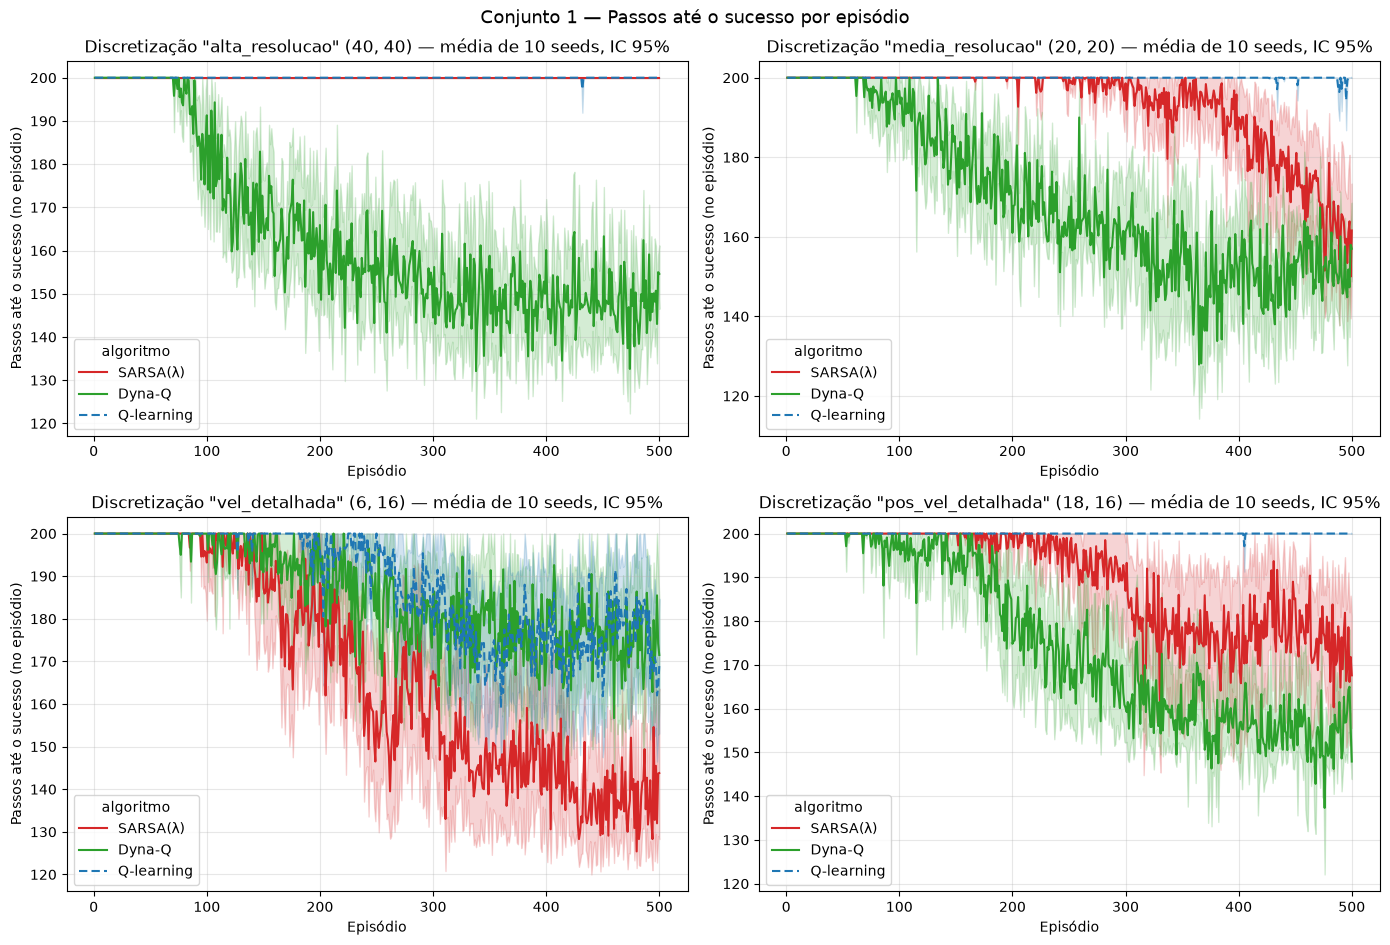

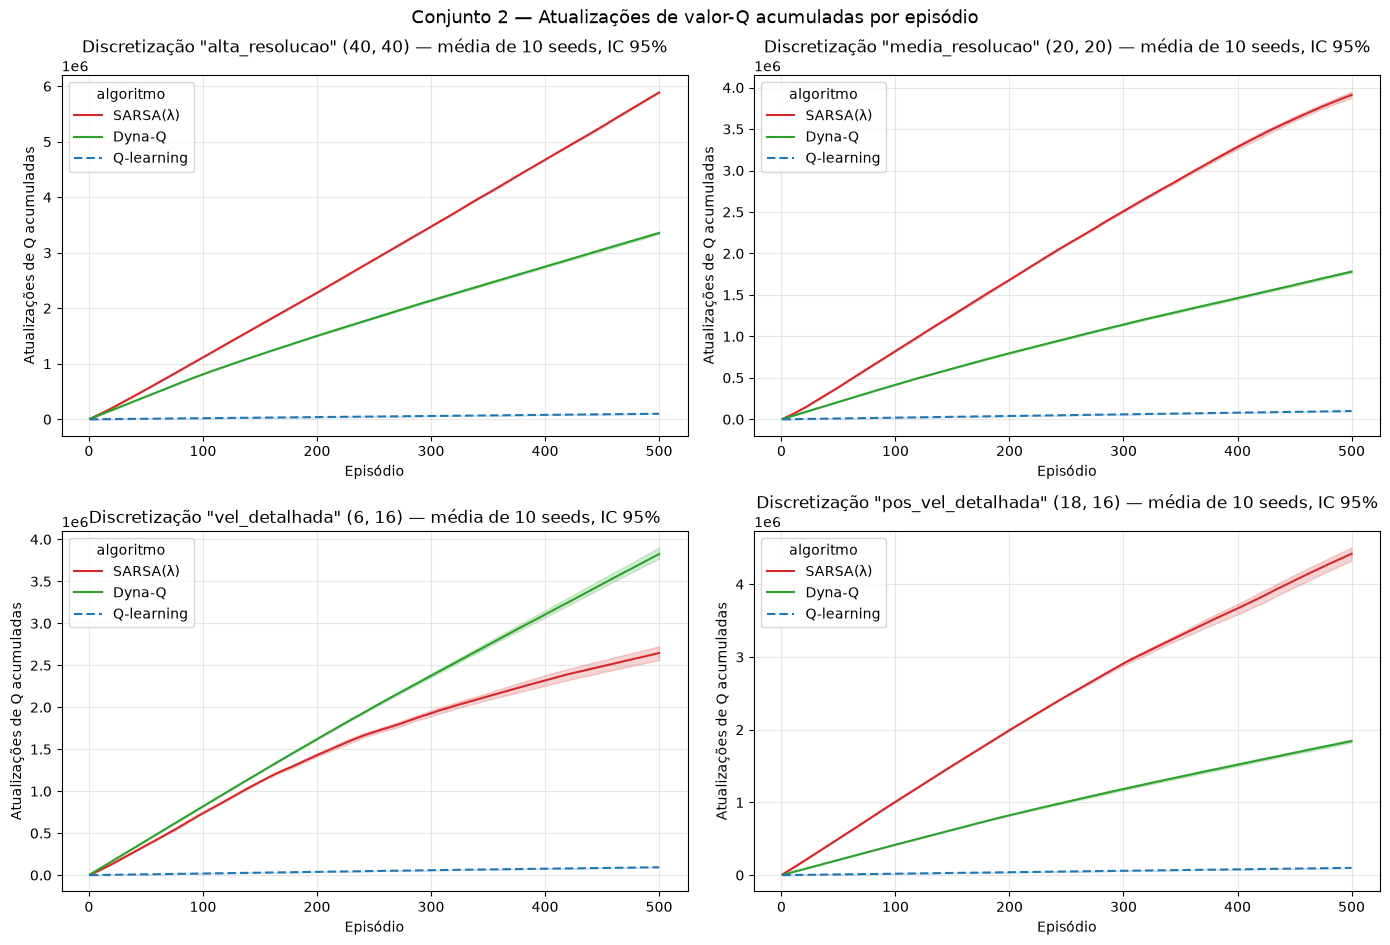

In [7]:
# ==============================================================================
# GRÁFICOS
# ==============================================================================
# Curva principal = média entre seeds; área sombreada = IC de 95%.
#   metodo_ic='bootstrap' -> seaborn.lineplot(errorbar=('ci', 95)) (bootstrap da média entre seeds)
#   metodo_ic='t'         -> média ± t_{0.975, n-1} · s/√n, calculado manualmente
# `suavizacao` > 1 aplica média móvel (por seed, antes de agregar) — escolha do aluno;
# o padrão 1 mostra os dados brutos.

CORES = {'Q-learning': '#1f77b4', 'SARSA(λ)': '#d62728', 'Dyna-Q': '#2ca02c'}
# Q-learning tracejado e desenhado por último (por cima): quando fica em 200 junto com outro
# algoritmo, as duas curvas continuam visíveis.
TRACEJADOS = {'Q-learning': (4, 2), 'SARSA(λ)': '', 'Dyna-Q': ''}
ORDEM_DESENHO = ['SARSA(λ)', 'Dyna-Q', 'Q-learning']
PASTA_FIGURAS = os.path.join(PASTA_RESULTADOS, 'figuras')
os.makedirs(PASTA_FIGURAS, exist_ok=True)


def _grade_de_eixos(n, largura=7, altura=4.8, colunas=2):
    """Figura com n subplots em até `colunas` colunas; esconde os eixos que sobrarem."""
    ncols = min(colunas, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(largura * ncols, altura * nrows), squeeze=False)
    axes = axes.ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes[:n]


def _suavizar(df, y, janela, grupo=('rotulo', 'seed')):
    if janela <= 1:
        return df
    df = df.copy()
    df[y] = df.groupby(list(grupo), sort=False)[y].transform(
        lambda v: v.rolling(janela, min_periods=1).mean())
    return df


def plotar_curvas(df, y, ax, x='episodio', hue='algoritmo', metodo_ic='bootstrap',
                  suavizacao=1, escala_log=False, titulo=None, rotulo_y=None, paleta=None):
    """Desenha, num eixo, uma curva (média + IC 95% sombreado) por valor de `hue`."""
    d = _suavizar(df, y, suavizacao, grupo=(hue, 'seed'))
    paleta = paleta if paleta is not None else (CORES if hue == 'algoritmo' else None)
    if metodo_ic == 'bootstrap':
        estilo = {}
        if hue == 'algoritmo':
            presentes = set(d[hue])
            estilo = dict(hue_order=[a for a in ORDEM_DESENHO if a in presentes], style=hue,
                          dashes={a: TRACEJADOS[a] for a in presentes})
        sns.lineplot(data=d, x=x, y=y, hue=hue, errorbar=('ci', 95), n_boot=1000, seed=0,
                     palette=paleta, ax=ax, **estilo)
    elif metodo_ic == 't':
        grupos = dict(list(d.groupby(hue, sort=False)))
        if hue == 'algoritmo':
            grupos = {a: grupos[a] for a in ORDEM_DESENHO if a in grupos}
        for i, (nome, g) in enumerate(grupos.items()):
            agg = g.groupby(x)[y].agg(['mean', 'std', 'count'])
            t = np.array([quantil_t(n - 1) if n > 1 else np.nan for n in agg['count']])
            meia = t * agg['std'] / np.sqrt(agg['count'])
            cor = paleta.get(nome) if isinstance(paleta, dict) else f'C{i}'
            ax.plot(agg.index, agg['mean'], label=nome, color=cor,
                    ls='--' if nome == 'Q-learning' else '-')
            ax.fill_between(agg.index, agg['mean'] - meia, agg['mean'] + meia, color=cor, alpha=0.2)
        ax.legend(title=hue)
    else:
        raise ValueError("metodo_ic deve ser 'bootstrap' ou 't'")
    if escala_log:
        ax.set_yscale('log')
    ax.set_xlabel('Episódio' if x == 'episodio' else x)
    ax.set_ylabel(rotulo_y or y)
    if titulo:
        ax.set_title(titulo)
    ax.grid(alpha=0.3)
    return ax


def plotar_conjunto(df, y, rotulo_y, titulo, nome_arquivo=None, **kwargs):
    """Um subplot por discretização, com os 3 algoritmos em cada um."""
    discs = list(dict.fromkeys(df['discretizacao']))
    fig, axes = _grade_de_eixos(len(discs))
    for ax, nome_disc in zip(axes, discs):
        bins = DISCRETIZADORES[nome_disc].bins if nome_disc in DISCRETIZADORES else ''
        n_seeds = df.loc[df.discretizacao == nome_disc, 'seed'].nunique()
        plotar_curvas(df[df.discretizacao == nome_disc], y, ax, rotulo_y=rotulo_y,
                      titulo=f'Discretização "{nome_disc}" {bins} — média de {n_seeds} seeds, IC 95%',
                      **kwargs)
    fig.suptitle(titulo, fontsize=13)
    fig.tight_layout()
    if nome_arquivo:
        fig.savefig(os.path.join(PASTA_FIGURAS, nome_arquivo), dpi=150, bbox_inches='tight')
    plt.show()
    return fig


# --- Conjunto 1: episódios (x) vs. passos até o sucesso (y) ----------------------
# Episódios que não chegam ao objetivo são truncados em MAX_PASSOS_EPISODIO passos
# (esse valor aparece como teto no gráfico).
fig_passos = plotar_conjunto(
    resultados, y='passos', rotulo_y='Passos até o sucesso (no episódio)',
    titulo='Conjunto 1 — Passos até o sucesso por episódio',
    nome_arquivo='conjunto1_passos_por_episodio.png', metodo_ic='bootstrap', suavizacao=1)

# --- Conjunto 2: episódios (x) vs. nº de atualizações de valor-Q (y) ------------------
# Aqui: atualizações ACUMULADAS desde o início do treino (custo computacional total).
# Para ver o custo por episódio, use y='atualizacoes_q_episodio'. Use escala_log=True se
# as curvas tiverem ordens de grandeza muito diferentes.
fig_atualiz = plotar_conjunto(
    resultados, y='atualizacoes_q_acumuladas', rotulo_y='Atualizações de Q acumuladas',
    titulo='Conjunto 2 — Atualizações de valor-Q acumuladas por episódio',
    nome_arquivo='conjunto2_atualizacoes_q.png', metodo_ic='bootstrap', escala_log=False)

### Apoio à análise (tabelas e gráficos complementares)

Tabela-resumo por configuração (média entre seeds ± IC 95%), recompensa vs. passos acumulados no ambiente e estatísticas do modelo aprendido pelo Dyna-Q (para a questão sobre *aliasing*). Esta célula apenas mede; a interpretação fica para a seção 4.2.

,discretizacao,algoritmo,rotulo,n_seeds,episodios,passos_medios_todos,passos_medios_todos_ic95,passos_medios_ult50,passos_medios_ult50_ic95,taxa_sucesso_ult50,taxa_sucesso_ult50_ic95,primeiro_sucesso_ep,primeiro_sucesso_ep_ic95,passos_ambiente_total,passos_ambiente_total_ic95,atualizacoes_q_total,atualizacoes_q_total_ic95,atualiz_q_por_passo,atualiz_q_por_passo_ic95,tempo_s,tempo_s_ic95
0,alta_resolucao,Q-learning,Q-learning,10,500,200,0.0122,200,0,0,0,432,NaN,1e+05,6.11,1e+05,6.11,1,0,12.5,1.61
1,alta_resolucao,SARSA(λ),SARSA(λ),10,500,200,0,200,0,0,0,NaN,NaN,1e+05,0,5.89e+06,1.55e+04,58.9,0.155,12.4,0.224
2,alta_resolucao,Dyna-Q,Dyna-Q,10,500,164,1.41,148,3.03,0.988,0.0121,83,4.96,8.19e+04,705,3.36e+06,2.89e+04,41,0,47.4,2.52
3,media_resolucao,Q-learning,Q-learning,10,500,200,0.0374,200,0.376,0.014,0.0136,452,25.9,1e+05,18.7,1e+05,18.7,1,0,12.1,0.837
4,media_resolucao,SARSA(λ),SARSA(λ),10,500,193,1.31,167,10.5,0.802,0.153,218,20.3,9.67e+04,654,3.91e+06,4.57e+04,40.5,0.271,8.94,0.265
5,media_resolucao,Dyna-Q,Dyna-Q,10,500,170,1.48,153,2.79,0.972,0.0168,81.9,10.3,8.48e+04,739,1.78e+06,1.55e+04,21,0,39.3,4.88
6,vel_detalhada,Q-learning,Q-learning,10,500,189,4.89,177,11.2,0.492,0.214,188,23.4,9.43e+04,2.44e+03,9.43e+04,2.44e+03,1,0,13.6,2.01
7,vel_detalhada,SARSA(λ),SARSA(λ),10,500,168,2.52,138,5.49,0.968,0.0532,112,20.1,8.4e+04,1.26e+03,2.65e+06,1.02e+05,31.5,0.956,9.19,0.241
8,vel_detalhada,Dyna-Q,Dyna-Q,10,500,187,3.81,175,7.78,0.568,0.165,110,23.3,9.33e+04,1.91e+03,3.82e+06,7.81e+04,41,0,47.1,1.46
9,pos_vel_detalhada,Q-learning,Q-learning,10,500,200,0.0131,200,0,0,0,405,NaN,1e+05,6.56,1e+05,6.56,1,0,13.1,1.26


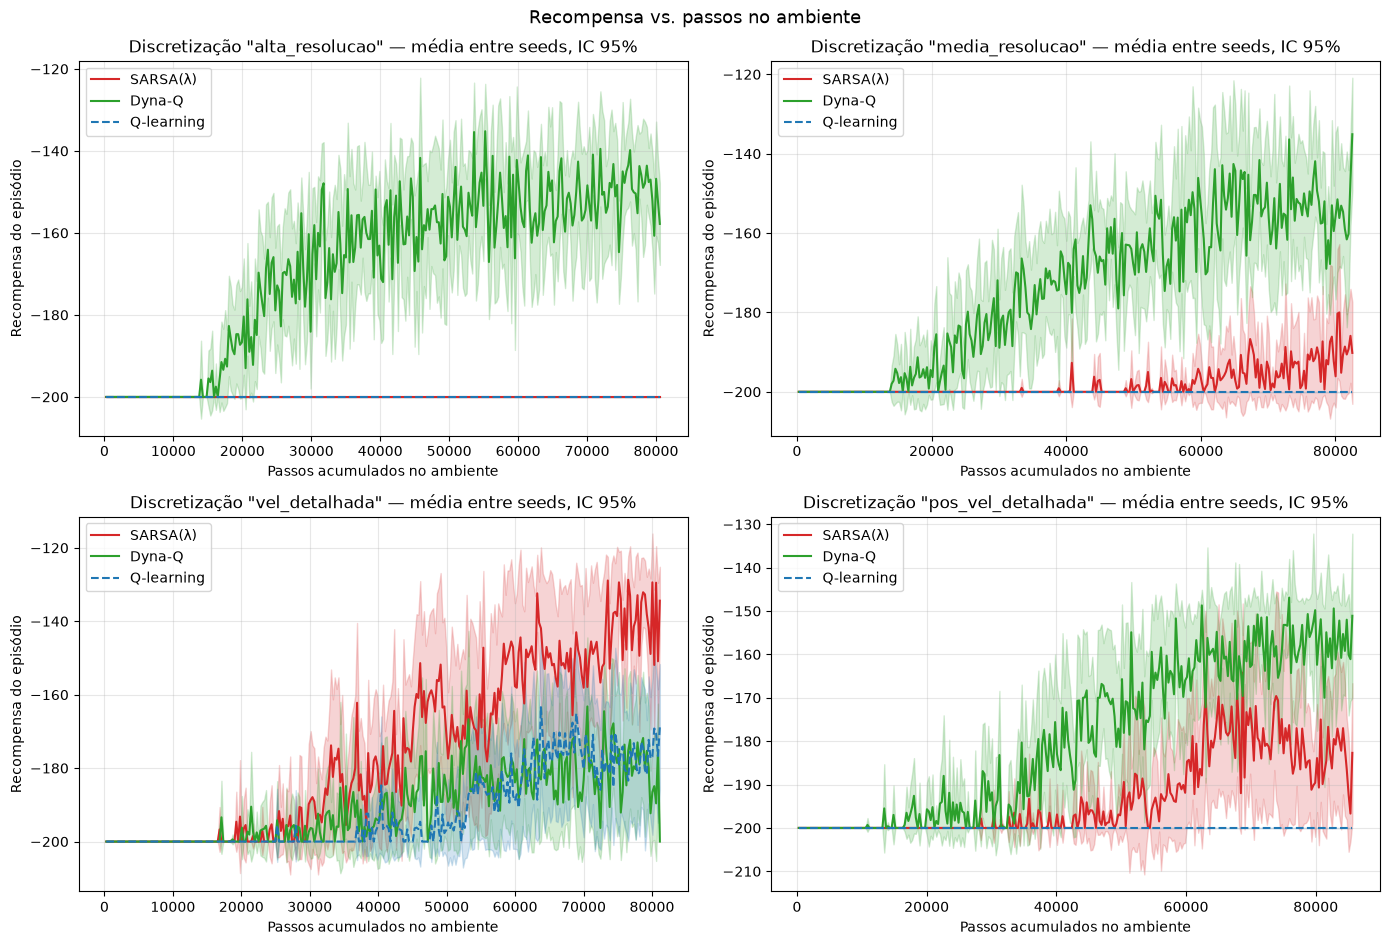

,,pares_observados,frac_tabela_observada,transicoes_registradas,frac_pares_nao_deterministicos,media_desfechos_distintos_por_par,max_desfechos_distintos_por_par,entropia_media_bits,entropia_media_ponderada_bits,frac_transicoes_para_mesmo_estado,pares_terminal_ambiguo
discretizacao,algoritmo,,,,,,,,,,
alta_resolucao,Dyna-Q,3.31e+03,0.69,8.19e+04,0.824,2.68,6,1.03,1.28,0.266,21.5
media_resolucao,Dyna-Q,815,0.679,8.48e+04,0.959,3.43,6,1.29,1.28,0.586,10
vel_detalhada,Dyna-Q,263,0.912,9.33e+04,0.969,3.34,5.5,0.96,1,0.663,9.2
pos_vel_detalhada,Dyna-Q,712,0.824,8.78e+04,0.947,3.1,5.8,1.03,1.13,0.543,8.4


In [8]:
# ==============================================================================
# APOIO À ANÁLISE (opcional): tabelas-resumo, recompensa vs. passos no ambiente e
# estatísticas do modelo do Dyna-Q (aliasing). Apenas MEDE; a interpretação é do aluno.
# ==============================================================================

# (1) Tabela-resumo: média entre seeds e meia-largura do IC 95% (colunas *_ic95)
ULTIMOS = 50   # janela de episódios finais usada nas métricas "ult"
resumo = tabela_resumo(resultados, ultimos=ULTIMOS)
resumo.to_csv(os.path.join(PASTA_RESULTADOS, 'resumo.csv'), index=False)
with pd.option_context('display.float_format', '{:,.3g}'.format, 'display.max_columns', 50):
    display(resumo)


# (2) Recompensa do episódio vs. passos acumulados no ambiente (eixo x = amostras usadas).
#     Cada seed é reamostrada numa grade comum de passos (valor = recompensa do episódio em
#     andamento naquele passo); depois, média ± IC 95% (t) entre seeds.
def plotar_recompensa_vs_passos(df, n_pontos=300, conf=0.95, nome_arquivo=None):
    discs = list(dict.fromkeys(df['discretizacao']))
    fig, axes = _grade_de_eixos(len(discs))
    for ax, nome_disc in zip(axes, discs):
        dd = df[df.discretizacao == nome_disc]
        x_max = dd.groupby(['algoritmo', 'seed']).passos_acumulados.max().min()
        grade = np.linspace(0, x_max, n_pontos)[1:]
        grupos = dict(list(dd.groupby('algoritmo', sort=False)))
        for nome_alg in [a for a in ORDEM_DESENHO if a in grupos]:
            g = grupos[nome_alg]
            curvas = []
            for _, gs in g.groupby('seed'):
                fim = gs.passos_acumulados.to_numpy()
                idx = np.searchsorted(fim, grade, side='left')   # episódio que contém o passo
                curvas.append(gs.recompensa.to_numpy()[np.minimum(idx, len(fim) - 1)])
            curvas = np.array(curvas)
            m = curvas.mean(axis=0)
            n = curvas.shape[0]
            h = quantil_t(n - 1, conf) * curvas.std(axis=0, ddof=1) / np.sqrt(n) if n > 1 else 0 * m
            cor = CORES.get(nome_alg)
            ax.plot(grade, m, label=nome_alg, color=cor, ls='--' if nome_alg == 'Q-learning' else '-')
            ax.fill_between(grade, m - h, m + h, color=cor, alpha=0.2)
        ax.set_xlabel('Passos acumulados no ambiente')
        ax.set_ylabel('Recompensa do episódio')
        ax.set_title(f'Discretização "{nome_disc}" — média entre seeds, IC 95%')
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle('Recompensa vs. passos no ambiente', fontsize=13)
    fig.tight_layout()
    if nome_arquivo:
        fig.savefig(os.path.join(PASTA_FIGURAS, nome_arquivo), dpi=150, bbox_inches='tight')
    plt.show()
    return fig


fig_recompensa = plotar_recompensa_vs_passos(resultados, nome_arquivo='recompensa_vs_passos.png')


# (3) Estatísticas do modelo aprendido pelo Dyna-Q (por discretização, média entre seeds).
#     - frac_pares_nao_deterministicos: fração dos (s,a) observados que levaram a mais de um s'
#     - entropia_media_*: entropia (bits) da distribuição empírica de desfechos por (s,a)
#     - frac_transicoes_para_mesmo_estado: fração das transições com s' == s
#     - pares_terminal_ambiguo: nº de (s,a) que às vezes terminaram o episódio e às vezes não
def tabela_modelo_dyna(pacotes):
    linhas = []
    for (nome_disc, nome_alg), pac in pacotes.items():
        for seed, est in pac['extras'].items():
            if est:
                linhas.append({'discretizacao': nome_disc, 'algoritmo': nome_alg, 'seed': seed, **est})
    if not linhas:
        return pd.DataFrame()
    return pd.DataFrame(linhas).drop(columns='seed').groupby(['discretizacao', 'algoritmo'], sort=False).mean()


with pd.option_context('display.float_format', '{:,.3g}'.format):
    display(tabela_modelo_dyna(PACOTES))

## 4.2 Análise de Resultados e Aliasing de Estados

*(Respondam de forma dissertativa, embasando-se nos gráficos gerados acima)*

### a) Qual o melhor algoritmo em termos de eficiência amostral?
O Dyna-Q foi o algoritmo mais eficiente em termos de amostras. Nas grades em que teve seu melhor
desempenho, ele chegou ao objetivo pela primeira vez por volta dos episódios 82 a 89, contra os
episódios 112 a 218 do SARSA(λ), e teve a menor média de passos ao longo de todo o treino (163,7 na
`alta_resolucao`, contra 168,1 do SARSA(λ) na `vel_detalhada`). Na `alta_resolucao`, foi o único
agente que aprendeu dentro dos 500 episódios. A exceção é a `vel_detalhada`, onde o SARSA(λ) foi
melhor que o Dyna-Q tanto ao longo do treino quanto no desempenho final.

Entre os agentes sem modelo, o SARSA(λ) foi claramente o melhor: o Q-learning praticamente não
aprendeu em três das quatro grades (média final entre 199,7 e 200) e, na `vel_detalhada`, chegou a
177,4, contra 138,2 do SARSA(λ). O Q-learning usa a configuração com a menor média encontrada na
busca (Q inicial = −100 e decaimento de ε de 0,9), mas a diferença para a configuração padrão não
foi significativa.

Comparando o melhor resultado de cada algoritmo, o desempenho final do SARSA(λ) foi
significativamente melhor: 138,2 ± 5,5 na `vel_detalhada`, contra 148,0 ± 3,0 do Dyna-Q na
`alta_resolucao`, com intervalos de confiança que não se sobrepõem. Isso não quer dizer que o
SARSA(λ) seja melhor em geral: a ordem entre os dois muda com a grade, e o Dyna-Q aprende mais
rápido.

Os resultados também mostram um padrão em relação ao número de estados. O Dyna-Q foi melhor nas
grades mais finas (148,0 na `alta_resolucao`, 153,2 na `media_resolucao` e 154,1 na
`pos_vel_detalhada`) e pior na `vel_detalhada`, de 96 células (174,8). Já o SARSA(λ) aprendeu mais
rápido com menos estados: na `vel_detalhada` teve o melhor resultado (138,2) e o primeiro sucesso
por volta do episódio 112, enquanto na `media_resolucao` o primeiro sucesso só veio por volta do
episódio 218. Uma hipótese, que não testamos porque nenhum treino passou de 500 episódios, é que o
Dyna-Q com mais estados ainda possa aprender mais com mais treino: o desempenho continuou
melhorando com mais planejamento (N = 10, 20 e 40 deram 165,7, 153,2 e 148,0 na `alta_resolucao`),
e as curvas ainda estavam caindo no fim do treino.

### b) Qual o melhor algoritmo em termos de eficiência computacional?
"Custo computacional" tem dois significados aqui, e eles discordam. Pelo critério do enunciado, o
número de atualizações de valores Q, o SARSA(λ) costuma ser mais caro que o Dyna-Q: 5,89 M contra
3,36 M na `alta_resolucao`, 3,91 M contra 1,78 M na `media_resolucao` e 4,42 M contra 1,84 M na
`pos_vel_detalhada`; só na `vel_detalhada` ele é mais barato (2,65 M contra 3,82 M). Pelo tempo de
relógio, porém, o SARSA(λ) é cerca de 4 vezes mais barato: 9 a 12 s por seed, contra 33 a 47 s do
Dyna-Q.

A diferença vem da forma das atualizações. No SARSA(λ), a cada passo todos os pares com traço
ativo recebem o mesmo erro TD, escalado pelo seu traço (Q ← Q + α·δ·e). O custo de um passo é
calcular um δ e fazer uma operação vetorial, não importa quantos pares ela atualize: milhares de
"atualizações" custam quase o mesmo que uma. No Dyna-Q, cada atualização de planejamento precisa
da sua própria amostra do modelo, do seu próprio alvo (um máximo sobre as ações do próximo estado)
e do seu próprio erro TD, ou seja, são N trabalhos separados por passo. No algoritmo original elas
também são sequenciais: cada atualização vê os valores deixados pela anterior. Por isso, vetorizar
o Dyna-Q exige mudar a ordem das operações, fazendo as N atualizações juntas, de forma síncrona.

Para verificar se a diferença de tempo vinha só da implementação, testamos uma versão do Dyna-Q com
o planejamento vetorizado em numpy (`mini_projeto_busca/benchmark_dyna_vetorizado.py`), com as
mesmas configurações finais e 10 seeds. O desempenho foi o mesmo (as diferenças ficaram dentro dos
intervalos de confiança nas quatro grades), e o tempo por seed caiu para 32,5 a 34,9 s, contra 32,6
a 47,4 s da versão original: cerca de 1,35 a 1,45 vez mais rápido com N = 40, 1,17 vez com N = 20
na `media_resolucao` e sem ganho na `pos_vel_detalhada`. Mesmo vetorizado, o Dyna-Q continuou cerca
de 3 vezes mais lento que o SARSA(λ), provavelmente porque um lote de N = 20 a 40 atualizações é
pequeno demais para compensar o custo fixo de cada chamada do numpy.

Em resumo, o Dyna-Q gasta computação para economizar amostras: aprende com menos interações com o
ambiente, mas cada passo real custa mais. Essa troca compensa quando interagir com o ambiente é
caro (um robô real ou um simulador lento) e a computação é barata. No MountainCar o simulador é
praticamente gratuito, então as atualizações baratas do SARSA(λ) são uma vantagem na prática, e
nenhum dos dois algoritmos é melhor em geral.

### c) Como a modelagem de estados afetou especificamente o modelo construído pelo Dyna-Q em comparação com o SARSA(λ)? Pense na relação entre as transições reais do ambiente vs nos estados discretizados.
Como usamos uma discretização, o modelo amostral (que guarda as contagens de todos os desfechos
de cada par (s, a) e sorteia de acordo com elas) foi o único tipo de modelo viável para o Dyna-Q.
O modelo "último desfecho" foi muito pior em todas as comparações: 199,5 contra 178,6 na
`baixa_resolucao` e 182,2 contra 165,7 na `alta_resolucao`, e de novo na rodada 2 (196,6 contra
165,7 e 186,6 contra 153,2). Outros parâmetros, como N e α, também tiveram efeito grande, mas entre
os tipos de modelo só o amostral funcionou.

Isso acontece porque uma célula da discretização agrupa muitos estados reais diferentes: o mesmo
par (s, a) discreto pode levar a próximos estados diferentes, então um ambiente determinístico
parece estocástico do ponto de vista do agente. O modelo "último desfecho" trata essas transições
como determinísticas e cria auto-laços errados, que o planejamento reforça. O SARSA(λ) não usa
modelo, então esse erro não existe para ele.

In [9]:
# ==============================================================================
# GRAVAÇÃO E EXIBIÇÃO DE VÍDEO DOS AGENTES TREINADOS
# ==============================================================================
# Salve um ou mais episódios dos seus agentes que valem a pena serem vistos
#
# A gravação usa a tabela Q FINAL salva em PACOTES (não é preciso re-treinar) e executa a
# política GULOSA (epsilon = 0). O vídeo (.mp4) é gerado pelo wrapper RecordVideo e exibido
# embutido no notebook (HTML5 + base64), o que funciona tanto no Colab quanto localmente.

PASTA_VIDEOS = os.path.join(PASTA_RESULTADOS, 'videos')


def politica_gulosa(q_values):
    """Política gulosa a partir de uma tabela Q (desempate: primeira ação de maior valor)."""
    return lambda s: int(np.argmax(q_values[s]))


def gravar_video(q_values, discretizacao, prefixo='agente', seed_ambiente=0,
                 max_passos_episodio=None, pasta=None):
    """Grava UM episódio da política gulosa. Devolve (caminho_mp4, passos, sucesso)."""
    disc = _obter_discretizador(discretizacao)
    max_passos_episodio = MAX_PASSOS_EPISODIO if max_passos_episodio is None else max_passos_episodio
    pasta = PASTA_VIDEOS if pasta is None else pasta
    os.makedirs(pasta, exist_ok=True)
    prefixo = _slug(prefixo)
    for antigo in glob.glob(os.path.join(pasta, f'{prefixo}-episode-*.mp4')):
        os.remove(antigo)   # evita exibir um vídeo antigo com o mesmo nome

    env = criar_ambiente(max_passos_episodio, render_mode='rgb_array')
    env = RecordVideo(env, video_folder=pasta, name_prefix=prefixo,
                      episode_trigger=lambda ep: True, disable_logger=True)
    pi = politica_gulosa(q_values)
    obs, _ = env.reset(seed=seed_ambiente)
    passos, terminou, truncou = 0, False, False
    while not (terminou or truncou):
        obs, r, terminou, truncou, _ = env.step(pi(disc(obs)))
        passos += 1
    env.close()   # fecha e grava o arquivo
    arquivos = sorted(glob.glob(os.path.join(pasta, f'{prefixo}-episode-*.mp4')), key=os.path.getmtime)
    if not arquivos:
        raise RuntimeError('Nenhum vídeo gerado (verifique se moviepy e pygame estão instalados).')
    return arquivos[-1], passos, bool(terminou)


def mostrar_video(caminho, largura=480):
    """Exibe um .mp4 embutido no notebook (Colab ou Jupyter local)."""
    with open(caminho, 'rb') as f:
        dados = base64.b64encode(f.read()).decode('ascii')
    return HTML(f'<video width="{largura}" controls loop autoplay muted>'
                f'<source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>')


def selecionar_seed(df, nome_disc, nome_alg, criterio='melhor', ultimos=50):
    """Seed com menor ('melhor') ou maior ('pior') média de passos nos últimos episódios."""
    d = df[(df.discretizacao == nome_disc) & (df.algoritmo == nome_alg)]
    medias = d.groupby('seed').apply(lambda g: g.passos.tail(ultimos).mean(), include_groups=False)
    return int(medias.idxmin() if criterio == 'melhor' else medias.idxmax())


# --- Vídeos discutidos na análise (item 4.2d) -------------------------------------------
# Durante os testes gravamos vídeos de todos os agentes em todas as discretizações; aqui ficam
# só os discutidos na análise. Para ver outros, acrescente pares (discretização, algoritmo).
VIDEOS = [
    ('alta_resolucao', 'Dyna-Q'),       # melhor resultado do Dyna-Q
    ('vel_detalhada', 'SARSA(λ)'),      # melhor resultado geral
    ('alta_resolucao', 'Q-learning'),   # exemplo de agente que não aprendeu a tarefa
]
SEED_AMBIENTE_VIDEO = 2024   # estado inicial do episódio gravado
for nome_disc, nome_alg in VIDEOS:
    seed = selecionar_seed(resultados, nome_disc, nome_alg, criterio='melhor')
    q = PACOTES[(nome_disc, nome_alg)]['q_tables'][seed]
    caminho, passos, sucesso = gravar_video(q, nome_disc, prefixo=f'{nome_disc}_{nome_alg}_seed{seed}',
                                            seed_ambiente=SEED_AMBIENTE_VIDEO)
    print(f'{nome_disc} | {nome_alg} | seed de treino {seed}: {passos} passos, '
          f'{"sucesso" if sucesso else "não chegou ao topo"} -> {caminho}')
    display(mostrar_video(caminho))


alta_resolucao | Dyna-Q | seed de treino 7: 153 passos, sucesso -> resultados\videos\alta_resolucao_Dyna-Q_seed7-episode-0.mp4


vel_detalhada | SARSA(λ) | seed de treino 6: 122 passos, sucesso -> resultados\videos\vel_detalhada_SARSA_lambda__seed6-episode-0.mp4


alta_resolucao | Q-learning | seed de treino 0: 200 passos, não chegou ao topo -> resultados\videos\alta_resolucao_Q-learning_seed0-episode-0.mp4


### d) Vídeos: quais agentes valem a pena ser vistos e por quê? (melhor desempenho, política inusitada, etc.)
Os vídeos escolhidos são: o Dyna-Q na `alta_resolucao`, que é o melhor resultado do Dyna-Q; o
SARSA(λ) na `vel_detalhada`, que é o melhor resultado geral; e o Q-learning na `alta_resolucao`,
como exemplo de agente que não aprendeu a tarefa. Durante os testes também gravamos vídeos de
todos os agentes nas outras discretizações, mas mantivemos aqui só os discutidos na análise.

## 4.3 Diário de Bordo e Registro de Falhas

O plano completo, as configurações testadas e o histórico de mudanças estão em
`mini_projeto_busca/PLANO_EXPERIMENTOS.md`; os números citados abaixo estão nas tabelas da pasta
`mini_projeto_busca/`. Todos os valores são a média de passos nos últimos 50 episódios (menor =
melhor; 200 = não chegou ao objetivo), média de 10 seeds.

### a) O que notadamente falhou nas escolhas de hiperparâmetros (alpha, decaimento de epsilon, λ, N)? Por que falharam?

- **α = 0,3:** derrubou o Dyna-Q na `baixa_resolucao` (199,6, contra 178,6 com α = 0,1). Um passo
  grande faz cada amostra nova sobrescrever o que foi aprendido, o que é pior com aliasing, porque
  amostras da mesma célula discordam. A hipótese de que α é o parâmetro mais sensível foi formulada
  *depois* desse resultado, então ele não conta como evidência; o primeiro teste de verdade foi
  α = 0,05, que ajudou o Dyna-Q na `baixa_resolucao` (165,7) mas piorou o Q-learning (198,1) e o
  SARSA(λ) (191,0).
- **Decaimento de ε:** o decaimento de 0,999 foi descartado antes de rodar, porque deixaria ε ≈ 0,30
  no episódio 500, ao contrário do que a literatura espera (convergir para a política gulosa). Os
  decaimentos de 0,95 e 0,9 mudaram muito o episódio do primeiro sucesso, mas pouco o desempenho
  final (no Dyna-Q da `baixa_resolucao`, todas as variações de exploração ficaram entre 178,0 e
  179,0).
- **λ:** λ maior ajudou até 0,9 (SARSA(λ) na `baixa_resolucao`: 184,6 com λ = 0; 174,0 com 0,7;
  150,4 com 0,9), mas λ = 0,99 piorou (168,6). Com γλ = 0,99 o traço quase não decai num episódio
  (0,99²⁰⁰ ≈ 0,13), então o tempo perdido muito antes do objetivo recebe quase o mesmo crédito que
  o balanço que funcionou, e a atualização fica com muita variância.
- **N:** N = 20 melhorou o Dyna-Q na `alta_resolucao` (153,2 contra 165,7), mas não na
  `baixa_resolucao`. N = 40 melhorou de novo (148,0), mas com ganho menor e custo dobrado (3,4 M
  atualizações de Q, contra 1,8 M).
- **γ = 0,9:** pior onde dava para distinguir (Dyna-Q na `baixa_resolucao`: 197,1). Com γ < 1, o
  sinal do objetivo encolhe a cada passo para trás (0,9¹⁰⁰ ≈ 0,00003), e balanços bons e ruins
  parecem quase iguais vistos do início.
- **Q inicial:** a hipótese de que −100 e −300 seriam piores que 0 foi refutada: foram iguais ou
  melhores (Q-learning na `baixa_resolucao`: 178,6 e 180,6, contra 188,2). Com γ = 1 e recompensa −1,
  a ação tentada sempre fica α abaixo das não tentadas, seja qual for o valor inicial, então o
  comportamento é o mesmo até o primeiro sucesso (−100 e −300 deram exatamente o mesmo episódio do
  primeiro sucesso). Depois disso, os valores do caminho se ancoram nos retornos reais, e um valor
  inicial baixo faz o agente se comprometer mais cedo com o caminho que encontrou.
- **Modelo "último desfecho" (Dyna-Q):** falhou (199,5 na `baixa_resolucao`, contra 178,6 do
  amostral), porque a discretização torna as transições aparentemente estocásticas.
- **Combinações dos melhores valores:** nenhuma combinação superou a melhor mudança isolada. Por
  exemplo, Q inicial = −100 ajudava o SARSA(λ) com λ = 0, mas piorou com λ = 0,9 acumulativo (159,0
  contra 147,3), ou seja, os fatores interagem.

### b) Houve alguma dificuldade ou erros na implementação de alguma etapa do projeto? Como foi resolvido?

- Usamos um assistente de IA para a parte braçal da implementação (algoritmos, scripts de busca e
  gráficos), como o enunciado permite, e para ajudar na redação; o desenho dos experimentos, as
  decisões e a análise são nossos, e conferimos os resultados.
- **Contagem de atualizações de Q:** foi preciso definir uma regra: 1 por passo no Q-learning, 1 por
  par com traço ativo no SARSA(λ) e 1 + N por passo no Dyna-Q.
- **Truncamento × término:** o limite de 200 passos não é um estado terminal, então nessas
  transições os agentes fazem bootstrap normalmente, e o modelo do Dyna-Q só guarda o término real.
- **Tamanho da busca:** a primeira versão da fase 2 incluía todos os valores empatados com o melhor
  e gerava 236 combinações (≈ 24 horas). Com 10 seeds, o teste tem pouco poder e quase tudo empata.
  Trocamos pela regra condicionada à evidência (só mudar um fator quando o padrão for
  significativamente pior), que resultou em 8 combinações.
- **Reprodutibilidade:** ao renomear as discretizações, os resultados salvos precisaram ser migrados
  (`renomear_resultados.py`). Além disso, os scripts da busca liam as grades da célula CONFIG do
  notebook, e isso quebrou a reprodução da busca quando a CONFIG passou a ter as grades finais; os
  scripts passaram a definir suas próprias grades.
- **Tempo de relógio:** o SARSA(λ) foi bem mais rápido que o Dyna-Q, apesar de fazer mais
  atualizações de Q. Para ver se isso vinha da implementação, testamos uma versão do Dyna-Q com o
  planejamento vetorizado (`benchmark_dyna_vetorizado.py`); o resultado está no item 4.2b.

### c) O que mais vale a pena relatar que não foi coberto nas demais perguntas?

- Algumas decisões foram tomadas depois de ver os resultados, e registramos isso: a hipótese sobre
  α e o critério do que contaria como resultado novo na busca coordenada.
- Paramos a busca por causa do prazo, embora o ganho com N ainda não tivesse saturado (N = 10, 20 e
  40). Trabalhos futuros: N maior, mais episódios e mais seeds.
- O desenho "um fator por vez" não testa interações, e com 10 seeds muitas diferenças ficam dentro
  do intervalo de confiança.
- Com 500 episódios, o Q-learning e o SARSA(λ) com a configuração padrão não aprenderam nas grades
  mais finas; o SARSA(λ) ajustado aprendeu na `media_resolucao` (151,7, contra 199,0 com o padrão),
  e só a `alta_resolucao` continuou fora do alcance dos agentes sem modelo.


## Apêndice (opcional): busca de hiperparâmetros

Ferramenta para conduzir uma busca de hiperparâmetros dentro do notebook: `gerar_grade(...)` monta a lista de configurações e `busca_hiperparametros(...)` roda cada uma com várias seeds, salva em disco e devolve uma tabela-resumo.

**Desligada por padrão:** a célula abaixo só roda se `EXECUTAR_BUSCA = True`. A busca usada neste trabalho foi feita fora do notebook, com os scripts da pasta `mini_projeto_busca/` (`busca.py`, `fase2.py` e `rodada2.py`; ver `PLANO_EXPERIMENTOS.md`), e os resultados ficam em `resultados/`. Esta célula fica aqui apenas para quem quiser experimentar outras configurações.


In [10]:
# ==============================================================================
# APÊNDICE: BUSCA DE HIPERPARÂMETROS (desligada por padrão)
# ==============================================================================
# Mude EXECUTAR_BUSCA para True para rodar. A grade abaixo é só um EXEMPLO de como usar
# as funções — quais parâmetros variar, quais valores testar e qual métrica usar para
# escolher a "melhor parametrização" são decisões do aluno.
EXECUTAR_BUSCA = False

if EXECUTAR_BUSCA:
    nome_disc_busca, nome_alg_busca = list(DISCRETIZACOES)[0], 'Dyna-Q'          # EXEMPLO
    grade = gerar_grade(HIPERPARAMETROS[nome_disc_busca][nome_alg_busca],         # EXEMPLO
                        n_planejamento=[5, 20], alpha=[0.1, 0.3])
    resumo_busca, episodios_busca = busca_hiperparametros(
        nome_alg_busca, nome_disc_busca, grade,
        seeds=SEEDS,               # pode usar menos seeds na busca e 10+ só na configuração final
        n_episodios=N_EPISODIOS)
    with pd.option_context('display.float_format', '{:,.3g}'.format, 'display.max_columns', 50):
        display(resumo_busca)

    # Curvas de todas as configurações testadas (uma cor por configuração)
    fig, ax = plt.subplots(figsize=(9, 5))
    plotar_curvas(episodios_busca, 'passos', ax, hue='rotulo', metodo_ic='t',
                  rotulo_y='Passos até o sucesso',
                  titulo=f'Busca: {nome_alg_busca} — discretização "{nome_disc_busca}"')
    plt.show()